# 20 · Birliktelik Kuralı Öğrenimi (Association Rule Learning: Apriori, Eclat, FP-Growth)

> **Bu notebook'ta ne öğreneceğiz?**
> Serinin denetimsiz bölümünün son "klasik" konusu: **"Hangi şeyler birlikte görülür?"** Etiket yok, hedef yok; elimizde sadece **sepetler** (işlemler) var — bir market fişi, bir web oturumunda gezilen sayfalar,
> bir hastanın aldığı tanılar, bir logda aynı anda tetiklenen alarmlar. Amaç `{A} → {B}` biçiminde, **veriden çıkan kuralları** bulmak ve bunlardan hangisinin *gerçekten* işe yaradığını ayırt etmek.
>
> 1. **Ölçüler:** `support`, `confidence`, `lift`, `leverage`, `conviction` — ne söylerler, **ne söyleyemezler**?
> 2. **Apriori:** "Sık olmayan kümenin üst kümesi de sık olamaz" ilkesi (anti-monotonluk) ile seviye seviye arama.
> 3. **Eclat:** Dikey (tid-list) gösterim + derinlik öncelikli arama; sayım = kesişim.
> 4. **FP-Growth:** Veriyi bir **FP-ağacına** sıkıştırıp aday üretmeden çıkarım.
> 5. **Kural üretimi, tekrar eden (redundant) kurallar, kapalı/maksimal kümeler.**
> 6. **Değerlendirme:** Kural "sık görünüyor" demek "gelecekte de geçerli" demek değildir → **zamana göre ayırma** ve **öneri (hit-rate)** deneyi.
>
> Üç algoritmayı **sıfırdan yazıp** `mlxtend` ile **birebir** karşılaştıracağız (aynı kümeler, aynı destekler); kural ölçülerini de sıfırdan yazıp doğrulayacağız.
>
> **Önkoşul:** 01 · Olasılık/koşullu olasılık (bkz. support ve confidence'ın olasılık dili), 16-17 · Kümeleme (denetimsiz düşünce), 11 · Değerlendirme (hold-out mantığı).
>
> **Veri (üçü de serinin önceki notebook'larında kullanılmadı):**
> - `Groceries` — gerçek bir market: **9.835 sepet, 171 ürün** (R `arules` paketinin klasik verisi; kaynak: Hahsler ve ark.). Algoritma doğrulama + öneri deneyi.
> - `Online Retail (UK)` — İngiltere'deki bir internet hediyelik eşya toptancısının **Aralık 2010 – Aralık 2011** faturaları (UCI Online Retail; Chen ve ark. 2012). Filtrelerden sonra **14.869 fatura, 404 ürün**: zamana göre ayırma ve mevsimsellik.
> - `Mushroom` — 8.124 mantar, 22 kategorik özellik (UCI/Audubon Field Guide). Özellik–sınıf kuralları; yoğun veride kapalı kümeler ve gereksiz kuralların patlaması.
>
> **Araçlar:** `mlxtend.frequent_patterns` (referans), R (`arules`), DuckDB (SQL — kendine-birleştirme ile destek/güven).

## 1 · Problem Tanımı ve Ölçüler

**Notasyon.** $\mathcal{I}=\{i_1,\dots,i_m\}$ ürün (öğe) kümesi; $\mathcal{D}=\{T_1,\dots,T_n\}$ işlemler, her $T_j\subseteq\mathcal{I}$. Bir **öğe kümesi (itemset)** $X\subseteq\mathcal{I}$.
Bir **kural** $X\Rightarrow Y$ ($X\cap Y=\emptyset$): "$X$'i içeren sepet çoğu zaman $Y$'yi de içerir".

| Ölçü | Formül | Olasılık dili | Ne anlatır? |
|---|---|---|---|
| **support** | $\mathrm{supp}(X)=\dfrac{\lvert\{T\in\mathcal{D}: X\subseteq T\}\rvert}{n}$ | $P(X)$ | Küme **ne kadar sık**? (kural için $\mathrm{supp}(X\cup Y)$) |
| **confidence** | $\mathrm{conf}(X\Rightarrow Y)=\dfrac{\mathrm{supp}(X\cup Y)}{\mathrm{supp}(X)}$ | $P(Y\mid X)$ | $X$ varken $Y$ **ne sıklıkla** var? |
| **lift** | $\mathrm{lift}=\dfrac{\mathrm{conf}(X\Rightarrow Y)}{\mathrm{supp}(Y)}=\dfrac{P(X\cap Y)}{P(X)P(Y)}$ | bağımsızlığa oran | $>1$ pozitif, $=1$ bağımsız, $<1$ negatif ilişki |
| **leverage** | $\mathrm{supp}(X\cup Y)-\mathrm{supp}(X)\,\mathrm{supp}(Y)$ | $P(XY)-P(X)P(Y)$ | Bağımsızlığa göre **mutlak** fazla sepet payı |
| **conviction** | $\dfrac{1-\mathrm{supp}(Y)}{1-\mathrm{conf}(X\Rightarrow Y)}$ | $P(X)P(\bar Y)/P(X\bar Y)$ | Kural **yanlış** çıkarsa ne kadar şaşırırız? ($\infty$: hiç yanlış yok) |

**Neden confidence tek başına yetmez?** $\mathrm{conf}(X\Rightarrow Y)$ yüksek olabilir çünkü $Y$ **zaten çok yaygın** (süt almak gibi). Lift bunu $\mathrm{supp}(Y)$ ile böler: "$Y$ rastgele bir sepette zaten
%65 oranında varsa, $X$ varken %70 olması çok bir şey söylemez." Ama lift de **nadir** $Y$ için şişer — iki ölçü birbirini tamamlar.

### 🔍 Somut örnek — 5 fişlik minik market (elle hesaplanabilir)

| Fiş | Sepet |
|---|---|
| $T_1$ | Ekmek, Süt |
| $T_2$ | Ekmek, Bez, Bira, Yumurta |
| $T_3$ | Süt, Bez, Bira, Kola |
| $T_4$ | Ekmek, Süt, Bez, Bira |
| $T_5$ | Ekmek, Süt, Bez, Kola |

Kural: **{Bez, Süt} ⇒ {Bira}** (klasik "bez–bira" efsanesi).

- $\mathrm{supp}(\{\text{Bez},\text{Süt}\})$: $T_3,T_4,T_5$ → $3/5=0{,}6$. $\mathrm{supp}(\{\text{Bez},\text{Süt},\text{Bira}\})$: $T_3,T_4$ → $2/5=0{,}4$. $\mathrm{supp}(\{\text{Bira}\})$: $T_2,T_3,T_4$ → $3/5=0{,}6$.
- $\mathrm{conf}=0{,}4/0{,}6=\mathbf{2/3\approx0{,}667}$.
- $\mathrm{lift}=0{,}667/0{,}6=\mathbf{1{,}11}$ → bağımsızlığa göre ancak **%11** fazla. Confidence "%67!" diye heyecan verici, lift "çok da değil" diyor.
- $\mathrm{leverage}=0{,}4-0{,}6\cdot0{,}6=\mathbf{0{,}04}$ → 5 fişin $0{,}04\cdot5=0{,}2$'si kadar fazla — **yani 5 fişte beklenenden 0,2 fiş fazla**; bu kadar küçük veride gürültüden ayırt edilemez.
- $\mathrm{conviction}=(1-0{,}6)/(1-0{,}667)=\mathbf{1{,}2}$.

Aynı veride **Kola ⇒ {Bez, Süt}**: confidence $=1$ (Kola'lı iki fişin ikisinde de var), lift $=1/0{,}6=1{,}67$ — çok güçlü *görünüyor* ama **destek 2 fiş**. Küçük destekte "mükemmel" kurallar şans eseri çıkar; bu notebook'un ana mesajlarından biri bu.

## 2 · Apriori — Anti-Monotonluk ile Seviye Seviye Arama

$m$ ürünle $2^m-1$ olası küme var (171 ürün için $\approx 3{,}8\times10^{51}$): kaba kuvvet imkânsız. Apriori'nin tek ama güçlü gözlemi:

> **Anti-monotonluk (downward closure):** $X\subseteq Z$ ise $\mathrm{supp}(X)\ge\mathrm{supp}(Z)$. Dolayısıyla **$X$ sık değilse, onu içeren hiçbir $Z$ de sık olamaz.**

*Kanıt (bir cümle):* $Z$'yi içeren her sepet $X$'i de içerir, yani $\{T: Z\subseteq T\}\subseteq\{T: X\subseteq T\}$.

**Algoritma** (eşik $\mathrm{minsup}$):

1. $L_1$ = destek $\ge\mathrm{minsup}$ olan tek ürünler. $k=2$.
2. **Aday üretimi (join):** $L_{k-1}$'deki, ilk $k-2$ öğesi aynı iki kümeyi birleştirip $k$-lı aday $C_k$ üret.
3. **Budama (prune):** $C_k$'deki adayın **tüm** $(k-1)$-alt kümeleri $L_{k-1}$'de değilse adayı **sayma bile** (anti-monotonluk).
4. **Sayım:** kalan adayların desteğini veritabanından say, $\ge\mathrm{minsup}$ olanlar $L_k$.
5. $L_k=\emptyset$ olunca dur. Sonuç $\bigcup_k L_k$.

### 🔍 Somut örnek — yukarıdaki 5 fiş, $\mathrm{minsup}=0{,}4$ (yani en az 2 fiş)

- $L_1$: Bez (4), Ekmek (4), Süt (4), Bira (3), Kola (2); **Yumurta (1) elenir**. ($C_1=6$ aday → $L_1=5$)
- $C_2$ = 5 ürünün $\binom52=10$ çifti. Sayımlar: Bez–Bira 3, Bez–Ekmek 3, Bez–Süt 3, Ekmek–Süt 3, Bez–Kola 2, Bira–Ekmek 2, Bira–Süt 2, Kola–Süt 2; **Bira–Kola (1) ve Ekmek–Kola (1) elenir** → $L_2$ = 8 çift.
- $C_3$: ortak ilk öğesi olan çiftleri birleştir → 7 birleşim: {Bez,Bira,Ekmek}, {Bez,Bira,Kola}, {Bez,Bira,Süt}, {Bez,Ekmek,Kola}, {Bez,Ekmek,Süt}, {Bez,Kola,Süt}, {Bira,Ekmek,Süt}. {Bez,Bira,Kola}'nın alt kümesi *Bira–Kola* sık değil, {Bez,Ekmek,Kola}'nın alt kümesi *Ekmek–Kola* sık değil → **2 aday budanır**, sayılmaz. Geriye 5 aday kalır.
- 5 adayın sayımı: {Bez,Bira,Ekmek} 2, {Bez,Bira,Süt} 2, {Bez,Ekmek,Süt} 2, {Bez,Kola,Süt} 2, {Bira,Ekmek,Süt} **1** (yalnız $T_4$) → $L_3$ = 4 küme. $C_4=\emptyset$, **dur**.

Toplam 5+8+4 = **17 sık küme**; $2^5-1=31$ olası kümenin hepsini saymaya gerek kalmadı (budamayla 2 adayın sayımı da atlandı). Bu sayıları aşağıda kodla doğrulayacağız.

**Maliyet:** Her seviye veritabanına bir geçiş (veya bit-kesişimi) ister; $C_2$ özellikle büyüktür ($\sim|L_1|^2/2$) — sık ürün çoksa Apriori'nin darboğazı **ikili adaylardır**.

## 3 · FP-Growth — Aday Üretmeden, Ağaçla

Apriori'nin pahalı kısmı (milyonlarca aday + tekrarlı sayım) şu fikirle atlanır: **veriyi iki geçişte bir FP-ağacına (frequent-pattern tree) sıkıştır**, sonra ağaçtan **özyinelemeli** çıkar.

1. **1. geçiş:** tek ürün desteklerini say, $\mathrm{minsup}$ altını at, kalanları **destekçe azalan** sırala (eşitlikte alfabetik).
2. **2. geçiş:** her sepeti bu sıraya göre dizip ağaca ekle; ortak önekler **paylaşılır** (sayaçlar artar). Her ürünün düğümleri bir **header** bağlı listesiyle erişilir.
3. **Madencilik:** ürünleri *en az sık olandan* başlayarak al. Her ürün $i$ için **koşullu desen tabanı** (conditional pattern base): $i$'nin her düğümünden köke giden yollar (sayaç = o düğümün sayacı). Bu tabandan *yeni bir ağaç* kurup aynı işlemi yinele; $\{i\}$ ile birleştirerek desenleri üret.

### 🔍 Somut örnek — aynı 5 fiş, sıra: Bez(4), Ekmek(4), Süt(4), Bira(3), Kola(2)

Sepetler sıralanınca: $T_1$: Ekmek–Süt · $T_2$: Bez–Ekmek–Bira · $T_3$: Bez–Süt–Bira–Kola · $T_4$: Bez–Ekmek–Süt–Bira · $T_5$: Bez–Ekmek–Süt–Kola.

```
root
├─ Ekmek:1 ─ Süt:1                          (T1)
└─ Bez:4
   ├─ Ekmek:3
   │   ├─ Bira:1                            (T2)
   │   └─ Süt:2
   │       ├─ Bira:1                        (T4)
   │       └─ Kola:1                        (T5)
   └─ Süt:1 ─ Bira:1 ─ Kola:1               (T3)
```

**Kola için koşullu desen tabanı:** {Bez, Ekmek, Süt}:1 ($T_5$), {Bez, Süt, Bira}:1 ($T_3$). Bu tabanda Bez 2, Süt 2, Ekmek 1, Bira 1 → $\mathrm{minsup}$ (2 fiş) ile sadece Bez ve Süt kalır → desenler: **{Kola,Bez}:2, {Kola,Süt}:2, {Kola,Bez,Süt}:2** — Apriori'nin bulduklarıyla aynı, ama **hiç aday üretmeden**.

**Neden hızlı?** Ağaç, tekrar eden önekleri tek yerde tutar (sıkıştırma); her adım *küçülen* bir alt problemdir. Dezavantaj: ağaç belleğe sığmalıdır ve çok seyrek/uzun-sepetli verilerde sıkıştırma azalır.

## 4 · Eclat — Dikey Gösterim ve Kesişim

Apriori ve FP-Growth sepet başına ürün listesi (yatay) kullanır. **Eclat** ürün başına **tid-list** (ürünü içeren sepet numaraları kümesi, dikey gösterim) tutar:

$$\mathrm{tid}(X\cup Y)=\mathrm{tid}(X)\cap\mathrm{tid}(Y),\qquad \mathrm{supp}(X\cup Y)=\frac{|\mathrm{tid}(X)\cap\mathrm{tid}(Y)|}{n}.$$

Sayım = küme kesişimi (veya **bit vektörü AND + popcount**, çok hızlı). Arama **derinlik öncelikli**: önek eşdeğerlik sınıfları içinde özyineleme, yeni tid-list = kesişim, desteği eşik altındaysa dal kesilir.

🔍 Örnek: $\mathrm{tid}(\text{Bez})=\{2,3,4,5\}$, $\mathrm{tid}(\text{Bira})=\{2,3,4\}$ → $\mathrm{tid}(\text{Bez,Bira})=\{2,3,4\}$, destek $3/5$ ✓.; $\mathrm{tid}(\text{Bez,Bira})\cap\mathrm{tid}(\text{Ekmek}=\{1,2,4,5\})=\{2,4\}$ → {Bez,Bira,Ekmek} desteği $2/5$ ✓ (Apriori'nin bulduğu 3'lü).

Eclat'ın avantajı: aday sayımı için veritabanı taraması yok; yoğun veride tid-list'ler uzun olduğundan **diffset** (iki tid-list'in farkı) varyantı belleği azaltır.

| | Apriori | FP-Growth | Eclat |
|---|---|---|---|
| Gösterim | yatay | FP-ağacı (sıkıştırılmış yatay) | dikey (tid-list) |
| Arama | genişlik öncelikli (seviye seviye) | böl-ve-yönet (koşullu ağaçlar) | derinlik öncelikli |
| Aday üretimi | **var** (join + prune) | yok | yok (ama kesişimle dolaylı) |
| Darboğaz | $C_2$ patlaması | ağacın belleğe sığması | tid-list boyutu |
| Çıktı | **aynı** sık kümeler | **aynı** | **aynı** |

Üçü de **aynı sonucu** verir — fark sadece hız/bellektir. Aşağıda bunu kodla da göstereceğiz.

## 5 · Kuralları Üretmek ve Değerlendirmek: Tuzaklar

**Kural üretimi.** Her sık küme $Z$ ($|Z|\ge2$) için tüm ayrışımlar $X\Rightarrow Z\setminus X$ denenir; $\mathrm{conf}\ge\mathrm{minconf}$ olanlar tutulur. Destek $\mathrm{supp}(Z)$, $\mathrm{supp}(X)$, $\mathrm{supp}(Z\setminus X)$ Apriori çıktısında **zaten var** (alt kümeler de sık), yeniden sayım gerekmez. Bir $|Z|=k$ kümesinden $2^k-2$ aday kural çıkar.

**Tuzaklar:**

1. **Küçük destek, "mükemmel" kural:** destek 2 fişse confidence=1 ve lift=1,67 şans olabilir. **Çok sayıda kural denendiğinde** (çoklu test) bir kısmı rastgele "ilginç" görünür → mutlaka **tutulan (hold-out) veride** doğrula.
2. **Nadir ürün problemi:** Tek bir $\mathrm{minsup}$ nadir ama değerli ürünleri (pahalı ürün, nadir hastalık) eler; düşürürsek kural sayısı patlar.
3. **Lift null-değişmez değildir:** "ne $X$ ne $Y$ içeren" sepetler (null işlemler) eklenirse $\mathrm{supp}$'lar küçülür, lift büyür — oysa $X$–$Y$ ilişkisi değişmedi. **Kulczynski** $\tfrac12\big(P(Y|X)+P(X|Y)\big)$ ve **imbalance ratio** null-değişmezdir (Han–Kamber–Pei).
4. **Gereksiz (redundant) kurallar:** $\{a\}\Rightarrow c$ confidence 1 ise $\{a,b\}\Rightarrow c$ de 1'dir ama **yeni bilgi yok**. Yoğun veride (Mushroom) binlerce kuralın çoğu böyledir → **kapalı küme** ve **minimal antecedent** ile budama.
5. **Nedensellik yok:** "bez ⇒ bira" bezin birayı *doğurduğunu* söylemez; ortak neden (cuma akşamı alışverişi) olabilir.

**Kapalı / maksimal kümeler.** Bir $X$ sık küme için:
- **Kapalı (closed):** hiçbir **üst kümesi aynı desteğe sahip değil**. Tüm sık kümelerin desteği kapalı kümelerden **kayıpsız** geri kurulur.
- **Maksimal (maximal):** hiçbir üst kümesi **sık değil**. Daha da küçük özet; ama alt kümelerin destekleri kaybolur.

Her maksimal küme kapalıdır; her kapalı küme sıktır: $\text{maksimal}\subseteq\text{kapalı}\subseteq\text{sık}$.

**Değerlendirme yolları.** (i) *Zaman ayırma:* eski sepetlerden kural çıkar, yeni sepetlerde destek/confidence/lift'in korunup korunmadığına bak. (ii) *Öneri görevi:* bir sepetten bir ürünü sakla, kalanlardan saklananı tahmin et ($\text{hit-rate}@k$); **popülerlik taban çizgisini** (hep en çok satılan $k$ ürünü öner) geçmek zorundasın.

## 6 · Pratikte Nerede Kullanılır?

| Alan | Sepet / öğe | Tipik kural | Not |
|---|---|---|---|
| Perakende | fiş / ürün | Bez + süt ⇒ bira (raf yerleşimi, kampanya paketi) | Ürün hiyerarşisi (kategori düzeyi) çoğu zaman marka düzeyinden daha kararlı |
| E-ticaret öneri | oturum / ürün | "Bunu alanlar şunu da aldı" | Büyük ölçekte matris/gömme modelleri (bkz. 23) üstün; kural tabanlı **açıklanabilir** ve ucuz |
| Web kullanım | oturum / sayfa | Ürün sayfası + yorum ⇒ sepet | Sıra önemliyse sıralı örüntü madenciliği (GSP/PrefixSpan) |
| Sağlık | hasta / tanı-ilaç | Tanı A + ilaç B ⇒ yan etki C | Sinyal üretir, **nedensellik kanıtı değildir**; çoklu test düzeltmesi şart |
| Güvenlik / BT | zaman penceresi / alarm | Alarm X + Y ⇒ olay Z | Anomali (19) ile birlikte kullanılır |
| Özellik mühendisliği | örnek / kategorik değer | `odor=n` ⇒ `class=e` | Kural-tabanlı sınıflandırıcılar (CBA) |

**Özet — bu notebook'un yol haritası**

| Adım | Ne yapacağız? | Neden? |
|---|---|---|
| 1 | Groceries'i tanı | Sepet boyutu ve ürün sıklığı dağılımı: neden destek eşikleri küçük? |
| 2 | 5 fişlik örneği kodla doğrula | Elle hesaplanan sayılar = kod çıktısı |
| 3 | Apriori, Eclat, FP-Growth'u sıfırdan yaz | `mlxtend` ile **aynı kümeler/destekler**; hız ve destek eşiği ilişkisi |
| 4 | Kuralları sıfırdan üret | Ölçüleri doğrula; hangi ölçü hangi kuralı öne çıkarır? |
| 5 | Online Retail (UK) kuralları | Gerçek, geniş sepetlerde ürün aileleri |
| 6 | **Zamana göre ayırma** | Hangi ölçü gelecekte daha kararlı? |
| 7 | **Öneri deneyi** (Groceries) | Kurallar popülerlik taban çizgisini geçer mi? |
| 8 | Mushroom: kapalı kümeler ve gereksiz kurallar | Yoğun veri, minimal antecedent, tek-özellik kuralı vs. |
| 9 | Null-değişmezlik | Lift mi, Kulczynski mi? |

# 🐍 Python Uygulaması

Adımlar:
1. `Groceries` verisinin yüklenmesi ve keşfi (sepet boyutu, ürün sıklığı)
2. 5 fişlik elle örneğin **kodla doğrulanması**
3. **Apriori, Eclat, FP-Growth** — sıfırdan; `mlxtend` ile birebir karşılaştırma; destek eşiğine göre küme sayısı ve süre (Online Retail)
4. **Kural üretimi** sıfırdan (support/confidence/lift/leverage/conviction), `mlxtend` ile doğrulama; ölçülerin sıralamaları ne kadar farklı?
5. Online Retail (UK): ürün aileleri, kural haritası
6. **Zamana göre ayırma:** ilk %70 fatura ile kural çıkar, son %30'da sına — hangi ölçü kararlı?
7. **Öneri deneyi** (Groceries): bir ürünü sakla, kalanlardan tahmin et; kurallar popülerliği geçer mi?
8. Mushroom: özellik→sınıf kuralları, **kapalı kümeler**, gereksiz kural patlaması, minimal antecedent
9. Null-değişmezlik: lift vs Kulczynski

In [1]:
import warnings
import itertools
import time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth as mx_fpgrowth, apriori as mx_apriori, association_rules as mx_rules

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.default_rng(42)

def to_onehot(transactions):
    """Sepet listesi -> bool DataFrame (mlxtend girdisi)."""
    te = TransactionEncoder()
    return pd.DataFrame(te.fit_transform(transactions), columns=te.columns_)

def fmt_set(s):
    return ' + '.join(sorted(s))

## Adım 1 · Groceries: Veriyi Tanıyalım

Her satır bir **fiş**; virgülle ayrılmış ürünler. Üç şeye bakıyoruz: sepet boyutu dağılımı, en sık ürünler ve **destek eşiği** seçmek için ürün sıklığının nasıl düştüğü.

Sepet sayısı: 9,835 | farklı ürün: 171 | ortalama sepet boyutu: 4.41 | medyan: 3 | maks: 32
Tek ürünlü sepet oranı: 22.0%

En sık 8 ürün (destek):
whole milk          0.2555
other vegetables    0.1935
rolls/buns          0.1839
soda                0.1744
yogurt              0.1395
bottled water       0.1105
root vegetables     0.1090
tropical fruit      0.1049


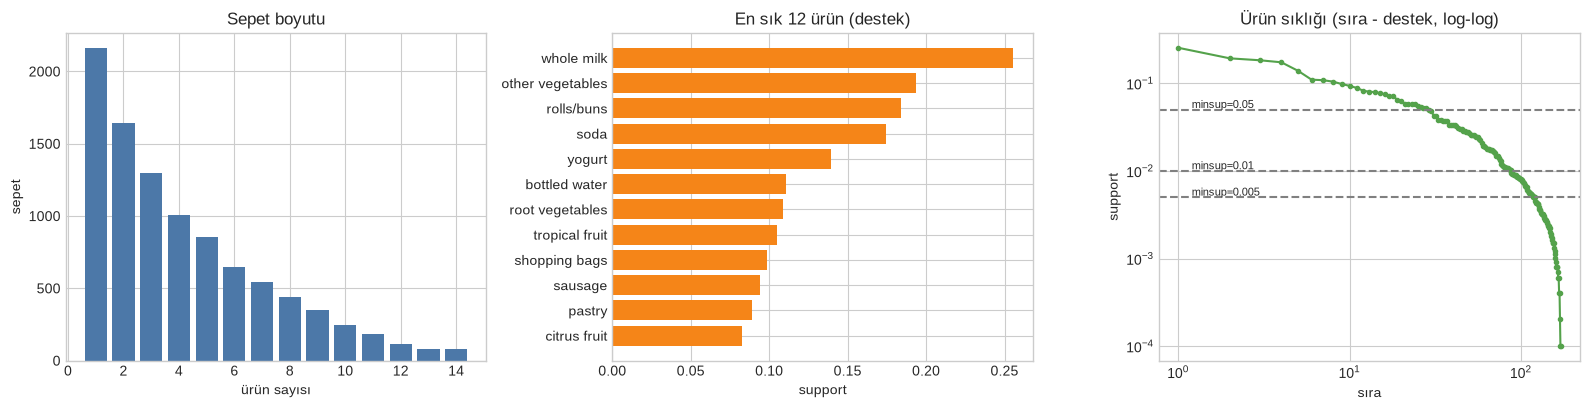

Destek >= %5: 28 ürün | >= %1: 87 ürün | >= %0,5: 120 ürün | toplam 171
YORUM: Sepetler küçük (ortalama ~4,4 ürün, %22'i tek ürünlü) ve ürün sıklığı çok eğik: 'whole milk' fişlerin ~%26'sında, ürünlerin yaklaşık yarısı ise %1'in altında.
       Bu yüzden minsup'ı %0,5-%2 bandında seçeceğiz; %5'te sadece birkaç ürün 'sık' sayılır (grafikteki kesikli çizgiler).


In [2]:
groceries = [sorted(set(line.strip().split(','))) for line in open('data/groceries.csv', encoding='utf-8')]
n_g = len(groceries)
sizes = np.array([len(t) for t in groceries])
item_cnt = pd.Series([i for t in groceries for i in t]).value_counts()

print(f"Sepet sayısı: {n_g:,} | farklı ürün: {item_cnt.size} | ortalama sepet boyutu: {sizes.mean():.2f} | medyan: {np.median(sizes):.0f} | maks: {sizes.max()}")
print(f"Tek ürünlü sepet oranı: {(sizes==1).mean():.1%}")
print("\nEn sık 8 ürün (destek):")
print((item_cnt.head(8) / n_g).round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(range(1, 15), np.bincount(sizes)[1:15], color='#4C78A8')
ax[0].set(title='Sepet boyutu', xlabel='ürün sayısı', ylabel='sepet')
ax[1].barh(item_cnt.head(12).index[::-1], (item_cnt.head(12) / n_g).values[::-1], color='#F58518')
ax[1].set(title='En sık 12 ürün (destek)', xlabel='support')
ax[2].loglog(np.arange(1, item_cnt.size + 1), item_cnt.values / n_g, '.-', color='#54A24B')
for ms in (0.05, 0.01, 0.005):
    ax[2].axhline(ms, ls='--', c='gray'); ax[2].text(1.2, ms * 1.05, f'minsup={ms}', fontsize=8)
ax[2].set(title='Ürün sıklığı (sıra - destek, log-log)', xlabel='sıra', ylabel='support')
plt.tight_layout(); plt.show()
fr = item_cnt / n_g
print(f"Destek >= %5: {(fr>=0.05).sum()} ürün | >= %1: {(fr>=0.01).sum()} ürün | >= %0,5: {(fr>=0.005).sum()} ürün | toplam {fr.size}")
print(f"YORUM: Sepetler küçük (ortalama ~4,4 ürün, %{(sizes==1).mean()*100:.0f}'i tek ürünlü) ve ürün sıklığı çok eğik: 'whole milk' fişlerin ~%26'sında, ürünlerin yaklaşık yarısı ise %1'in altında.")
print("       Bu yüzden minsup'ı %0,5-%2 bandında seçeceğiz; %5'te sadece birkaç ürün 'sık' sayılır (grafikteki kesikli çizgiler).")

## Adım 2 · 5 Fişlik Elle Örneği Kodla Doğrulama

Teori bölümündeki sayıları (Apriori seviyeleri: 6→5, 10→8, 5→4; kural ölçüleri) **tek tek** kodla yeniden üretelim. Önce algoritmaları yazmamız gerekiyor — aşağıdaki Adım 3'te yazıp burada kullanacağız; o yüzden önce algoritma hücreleri.

### Adım 3a · Apriori (sıfırdan)

Sayım adımı için her ürüne bir **bit vektörü** (Python `int`; $k$. bit = $k$. sepette var mı) veriyoruz — "veritabanını tarayıp say" işlemi bit-AND + `bit_count()` olur ve çok hızlıdır. **Aday üretimi (join) ve budama (prune) tam Apriori'dir:** birleştirilen iki kümenin ilk $k-2$ öğesi aynı olmalı; adayın tüm $(k-1)$-alt kümeleri sık olmalı. Her seviye için `(k, aday sayısı, sık küme sayısı)` döndürüyoruz.

In [3]:
def build_tidlists(transactions):
    """Ürün -> bit vektörü (k. bit = ürün k. sepette)."""
    tid = {}
    for k, t in enumerate(transactions):
        for i in t:
            tid[i] = tid.get(i, 0) | (1 << k)
    return tid

def apriori_scratch(transactions, min_support):
    n = len(transactions); tid = build_tidlists(transactions)
    minc = int(np.ceil(min_support * n - 1e-9))                 # en az bu kadar sepet
    L1 = {(i,): tid[i].bit_count() for i in sorted(tid) if tid[i].bit_count() >= minc}
    freq = dict(L1); prev = sorted(L1); bits = {c: tid[c[0]] for c in prev}
    stats = [(1, len(tid), len(L1))]; k = 2
    while prev:
        prev_set = set(prev); cands = []
        for a, b in itertools.combinations(prev, 2):
            if a[:-1] == b[:-1]:                                # JOIN: ilk k-2 öğe ortak
                c = a + (b[-1],)
                if all(c[:j] + c[j + 1:] in prev_set for j in range(k - 1)):   # PRUNE: tüm (k-1)-alt kümeler sık
                    cands.append((c, a, b))
        cur, new_bits = {}, {}
        for c, a, b in cands:                                   # SAYIM
            bt = bits[a] & bits[b]; s = bt.bit_count()
            if s >= minc:
                cur[c] = s; new_bits[c] = bt
        stats.append((k, len(cands), len(cur)))
        freq.update(cur); prev = sorted(cur); bits = new_bits; k += 1
    return {frozenset(c): s / n for c, s in freq.items()}, stats

### Adım 3b · Eclat (sıfırdan)

Aynı bit vektörleri, ama **derinlik öncelikli**: `cands` (aynı önekten genişleyen ürünler ve tid-list'leri) içinde her ürün için bir sık küme kaydet, sonra sonraki kardeşlerle kesiştirip özyinele. Seviye seviye gezme ve budama yok — eşik altı kesişim dalı doğrudan keser.

In [4]:
def eclat_scratch(transactions, min_support):
    n = len(transactions); tid = build_tidlists(transactions)
    minc = int(np.ceil(min_support * n - 1e-9)); out = {}
    base = sorted((i, b) for i, b in tid.items() if b.bit_count() >= minc)
    def rec(prefix, cands):
        for idx, (i, b) in enumerate(cands):
            out[frozenset(prefix + (i,))] = b.bit_count() / n
            ext = []
            for j, bj in cands[idx + 1:]:
                nb_ = b & bj                                    # tid-list kesişimi
                if nb_.bit_count() >= minc:
                    ext.append((j, nb_))
            if ext:
                rec(prefix + (i,), ext)
    rec((), base)
    return out

### Adım 3c · FP-Growth (sıfırdan)

Üç parça: (1) **FP-ağacı kurma** (sıralı sepetleri ortak önekleri paylaşarak ekle, her ürünün düğümlerini `link` ile bağla), (2) her ürün için **koşullu desen tabanı** (düğümden köke yollar, düğümün sayacıyla ağırlıklı), (3) özyinelemeli madencilik. Koşullu tabanlarda sepetler **ağırlıklıdır** (`(yol, sayaç)`), bu yüzden fonksiyon ağırlıklı girdi alır.

In [5]:
class FPNode:
    __slots__ = ('item', 'count', 'parent', 'children', 'link')
    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children, self.link = item, 0, parent, {}, None

def fp_build(weighted, order):
    """weighted: [(öğe listesi, ağırlık)]. order: öğe -> sıra (küçük = daha sık). (kök, header) döner."""
    root = FPNode(None, None); header = {}
    for t, w in weighted:
        cur = root
        for i in sorted((x for x in t if x in order), key=order.get):
            ch = cur.children.get(i)
            if ch is None:
                ch = FPNode(i, cur); cur.children[i] = ch
                ch.link = header.get(i); header[i] = ch         # header bağlı listesi
            ch.count += w; cur = ch
    return root, header

def fp_mine(weighted, minc, suffix, out, n):
    cnt = defaultdict(int)
    for t, w in weighted:
        for i in t: cnt[i] += w
    freq = {i: c for i, c in cnt.items() if c >= minc}
    order = {i: r for r, i in enumerate(sorted(freq, key=lambda i: (-freq[i], i)))}
    _, header = fp_build(weighted, order)
    for i in sorted(freq, key=order.get, reverse=True):         # en az sık ürünten başla
        new = suffix | {i}; out[frozenset(new)] = freq[i] / n
        cond, node = [], header[i]                              # koşullu desen tabanı
        while node is not None:
            path, p = [], node.parent
            while p.item is not None:
                path.append(p.item); p = p.parent
            if path: cond.append((path, node.count))
            node = node.link
        if cond: fp_mine(cond, minc, new, out, n)

def fpgrowth_scratch(transactions, min_support):
    n = len(transactions); minc = int(np.ceil(min_support * n - 1e-9)); out = {}
    fp_mine([(t, 1) for t in transactions], minc, frozenset(), out, n)
    return out

### Adım 3d · Kural üretimi (sıfırdan)

Her sık küme $Z$ için tüm $X\Rightarrow Z\setminus X$ ayrışımları; destekler sözlükte hazır. Beş ölçüyü de hesaplıyoruz. `conviction`: $\mathrm{conf}=1$ ise $\infty$.

In [6]:
def rules_scratch(sup, min_conf=0.0):
    """sup: {frozenset: destek} (alt kümeleri de içeren tam sık-küme sözlüğü). DataFrame döner (A, B frozenset)."""
    rows = []
    for Z, s in sup.items():
        if len(Z) < 2: continue
        items = list(Z)
        for r in range(1, len(items)):
            for A in itertools.combinations(items, r):
                A = frozenset(A); B = Z - A
                sa, sb = sup[A], sup[B]; conf = s / sa
                if conf < min_conf: continue
                rows.append((A, B, sa, sb, s, conf, conf / sb, s - sa * sb,
                             (1 - sb) / (1 - conf) if conf < 1 else np.inf))
    return pd.DataFrame(rows, columns=['A', 'B', 'sup_A', 'sup_B', 'support', 'confidence', 'lift', 'leverage', 'conviction'])

def show_rules(R, by, k=8, cols=('support', 'confidence', 'lift', 'leverage')):
    out = R.sort_values(by, ascending=False).head(k).copy()
    out['kural'] = out.A.map(fmt_set) + '  =>  ' + out.B.map(fmt_set)
    return out[['kural', *cols]].round(4).to_string(index=False)

In [7]:
mini = [['Ekmek', 'Süt'], ['Ekmek', 'Bez', 'Bira', 'Yumurta'], ['Süt', 'Bez', 'Bira', 'Kola'],
        ['Ekmek', 'Süt', 'Bez', 'Bira'], ['Ekmek', 'Süt', 'Bez', 'Kola']]
sup_mini, stats_mini = apriori_scratch(mini, 0.4)
print("Apriori seviyeleri (k, aday sayısı, sık küme sayısı):", stats_mini)
print("Toplam sık küme:", len(sup_mini), "(elle: 5 + 8 + 4 = 17)")
print("\n3'lü sık kümeler ve fiş sayıları:")
for Z, s in sorted(sup_mini.items(), key=lambda kv: (len(kv[0]), sorted(kv[0]))):
    if len(Z) == 3: print("  ", fmt_set(Z), round(s * 5))

R_mini = rules_scratch(sup_mini)
r = R_mini[(R_mini.A == frozenset({'Bez', 'Süt'})) & (R_mini.B == frozenset({'Bira'}))].iloc[0]
print(f"\n{{Bez,Süt}} => {{Bira}}: support={r.support:.2f}, confidence={r.confidence:.3f}, lift={r.lift:.3f}, leverage={r.leverage:.2f}, conviction={r.conviction:.2f}")
print("(elle: 0.40, 0.667, 1.11, 0.04, 1.2)")
r = R_mini[(R_mini.A == frozenset({'Kola'})) & (R_mini.B == frozenset({'Bez', 'Süt'}))].iloc[0]
print(f"{{Kola}} => {{Bez,Süt}}: confidence={r.confidence:.2f}, lift={r.lift:.3f}, destek = {round(r.support*5)} fiş")
assert sup_mini == eclat_scratch(mini, 0.4) == fpgrowth_scratch(mini, 0.4)
print("\nApriori == Eclat == FP-Growth (küme ve destekler birebir): True")
print("YORUM: Elle yürüttüğümüz sayılar kodla birebir tutuyor — 6->5, 10->8, 5->4 aday/sık küme sayıları dahil. {Kola}=>{Bez,Süt} 'kusursuz' görünse de yalnızca 2 fişe dayanıyor.")

Apriori seviyeleri (k, aday sayısı, sık küme sayısı): [(1, 6, 5), (2, 10, 8), (3, 5, 4), (4, 0, 0)]
Toplam sık küme: 17 (elle: 5 + 8 + 4 = 17)

3'lü sık kümeler ve fiş sayıları:
   Bez + Bira + Ekmek 2
   Bez + Bira + Süt 2
   Bez + Ekmek + Süt 2
   Bez + Kola + Süt 2

{Bez,Süt} => {Bira}: support=0.40, confidence=0.667, lift=1.111, leverage=0.04, conviction=1.20
(elle: 0.40, 0.667, 1.11, 0.04, 1.2)
{Kola} => {Bez,Süt}: confidence=1.00, lift=1.667, destek = 2 fiş

Apriori == Eclat == FP-Growth (küme ve destekler birebir): True
YORUM: Elle yürüttüğümüz sayılar kodla birebir tutuyor — 6->5, 10->8, 5->4 aday/sık küme sayıları dahil. {Kola}=>{Bez,Süt} 'kusursuz' görünse de yalnızca 2 fişe dayanıyor.


## Adım 3 · Üç Algoritma `mlxtend` ile Aynı mı? Hız Nasıl Değişiyor?

Önce Groceries'te üç algoritmanın çıktısını `mlxtend`'in `fpgrowth`'ı ile **küme ve destek düzeyinde** karşılaştırıyoruz. Sonra **Online Retail (UK)** üzerinde destek eşiğini düşürürken küme sayısını ve süreyi ölçüyoruz (fatura başına ortalama 14,2 ürünlük geniş sepetler).

In [8]:
X_g = to_onehot(groceries)
rows = []
for ms in (0.02, 0.01, 0.005):
    mx = mx_fpgrowth(X_g, min_support=ms, use_colnames=True)
    ref = {frozenset(r.itemsets): r.support for r in mx.itertuples()}
    res = {}
    for name, fn in (('Apriori', lambda: apriori_scratch(groceries, ms)[0]), ('Eclat', lambda: eclat_scratch(groceries, ms)),
                     ('FP-Growth', lambda: fpgrowth_scratch(groceries, ms))):
        res[name] = fn()
        same = set(res[name]) == set(ref)
        maxdiff = max(abs(res[name][k] - ref[k]) for k in ref) if same else np.nan
        rows.append(dict(minsup=ms, algoritma=name, küme_sayısı=len(res[name]), mlxtend_aynı_küme=same, maks_destek_farkı=maxdiff))
print(pd.DataFrame(rows).to_string(index=False))
print("\nApriori seviyeleri (minsup=0.005):", apriori_scratch(groceries, 0.005)[1])
print("YORUM: Üç sıfırdan uygulama da mlxtend ile AYNI sık kümeleri ve AYNI destekleri (destek farkı 0,0) üretiyor. Apriori seviye çıktısı budamanın etkisini gösterir:")
print("       2'li aday sayısı (7140) 3'lü ve 4'lü adaylardan çok büyük - Apriori'nin darboğazı gerçekten ikili adaylar.")

 minsup algoritma  küme_sayısı  mlxtend_aynı_küme  maks_destek_farkı
  0.020   Apriori          122               True                0.0
  0.020     Eclat          122               True                0.0
  0.020 FP-Growth          122               True                0.0
  0.010   Apriori          332               True                0.0
  0.010     Eclat          332               True                0.0
  0.010 FP-Growth          332               True                0.0
  0.005   Apriori         1000               True                0.0
  0.005     Eclat         1000               True                0.0
  0.005 FP-Growth         1000               True                0.0

Apriori seviyeleri (minsup=0.005): [(1, 171, 120), (2, 7140, 604), (3, 3444, 264), (4, 152, 12), (5, 0, 0)]
YORUM: Üç sıfırdan uygulama da mlxtend ile AYNI sık kümeleri ve AYNI destekleri (destek farkı 0,0) üretiyor. Apriori seviye çıktısı budamanın etkisini gösterir:
       2'li aday sayısı (7140) 3'lü ve 4

Online Retail (UK): 14,869 fatura, 404 ürün, ort. sepet 14.2 ürün, 2010-12-01 .. 2011-12-09


        Apriori (s)  Eclat (s)  FP-Growth (s)  mlxtend FP (s)  sık küme  maks. boyut
minsup                                                                              
0.050          0.07       0.07           0.16            0.24        61            2
0.030          0.12       0.08           0.65            0.98       235            3
0.020          0.34       0.23           1.51            2.03       587            3
0.015          0.47       0.16           1.20            2.31       943            4
0.010          0.43       0.23           1.95            2.89      2870            5
0.005         26.00       1.57           7.82           10.36     37883            8


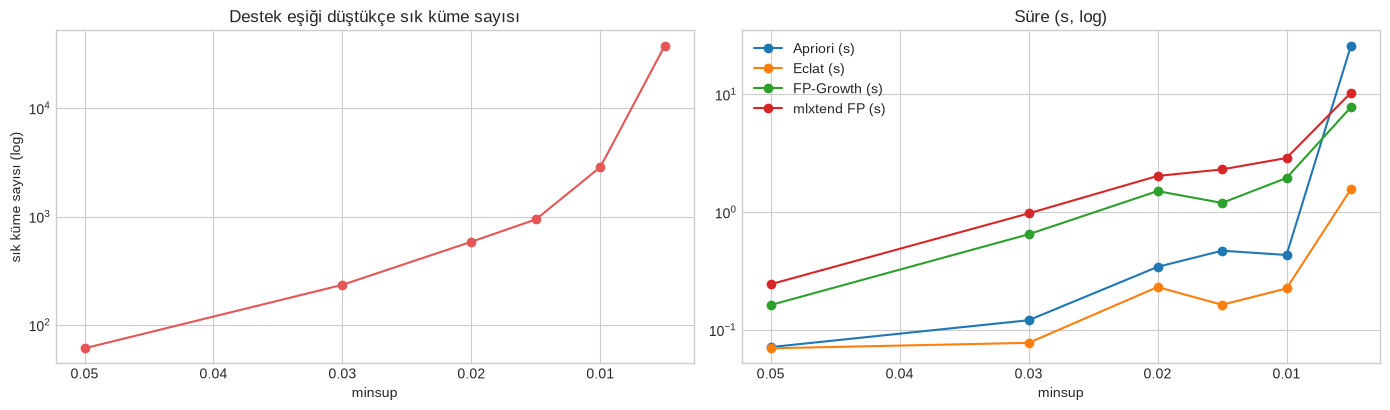

In [9]:
ret = pd.read_csv('data/online_retail_uk.csv.gz', parse_dates=['date'])
inv = ret.groupby('invoice').agg(date=('date', 'min'), items=('item', lambda s: sorted(set(s)))).sort_values('date')
retail = inv['items'].tolist(); retail_dates = inv['date'].to_numpy(); n_r = len(retail)
print(f"Online Retail (UK): {n_r:,} fatura, {ret.item.nunique()} ürün, ort. sepet {np.mean([len(t) for t in retail]):.1f} ürün, "
      f"{inv.date.min():%Y-%m-%d} .. {inv.date.max():%Y-%m-%d}")
X_r = to_onehot(retail)

rows = []
for ms in (0.05, 0.03, 0.02, 0.015, 0.01, 0.005):
    r = dict(minsup=ms)
    for name, fn in (('Apriori', lambda: apriori_scratch(retail, ms)[0]), ('Eclat', lambda: eclat_scratch(retail, ms)),
                     ('FP-Growth', lambda: fpgrowth_scratch(retail, ms))):
        t0 = time.perf_counter(); out = fn(); r[name + ' (s)'] = time.perf_counter() - t0
    t0 = time.perf_counter(); mx = mx_fpgrowth(X_r, min_support=ms, use_colnames=True); r['mlxtend FP (s)'] = time.perf_counter() - t0
    assert set(out) == {frozenset(x) for x in mx.itemsets}
    r['sık küme'] = len(out); r['maks. boyut'] = max(len(k) for k in out)
    rows.append(r)
scal = pd.DataFrame(rows).set_index('minsup')
print(scal.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].semilogy(scal.index, scal['sık küme'], 'o-', color='#E45756'); ax[0].invert_xaxis()
ax[0].set(title='Destek eşiği düştükçe sık küme sayısı', xlabel='minsup', ylabel='sık küme sayısı (log)')
for c in ('Apriori (s)', 'Eclat (s)', 'FP-Growth (s)', 'mlxtend FP (s)'): ax[1].semilogy(scal.index, scal[c], 'o-', label=c)
ax[1].invert_xaxis(); ax[1].legend(); ax[1].set(title='Süre (s, log)', xlabel='minsup')
plt.tight_layout(); plt.show()

In [10]:
print("YORUM: Destek eşiğini %5'ten %0,5'e indirirken sık küme sayısı katlanarak artıyor (üstel büyüme eğilimi). Üç sıfırdan algoritma da mlxtend ile aynı kümeleri buldu (assert geçti).")
fastest = scal[['Apriori (s)', 'Eclat (s)', 'FP-Growth (s)', 'mlxtend FP (s)']].idxmin(axis=1).value_counts().to_dict()
print("Her eşik için en hızlı yöntem:", fastest)
lo = scal.loc[0.005]
print(f"En düşük eşikte (minsup=0.005) süreler: Apriori {lo['Apriori (s)']:.1f} s | Eclat {lo['Eclat (s)']:.1f} s | FP-Growth {lo['FP-Growth (s)']:.1f} s | mlxtend FP {lo['mlxtend FP (s)']:.1f} s; en büyük sık küme {int(lo['maks. boyut'])} ürünlük.")
print("Okuma: Yüksek eşiklerde bit-vektörlü Apriori/Eclat en hızlısı; ama eşik düşüp uzun desenler (8 ürünlük) çıkınca Apriori'nin aday üretimi patlıyor ve FP-Growth/Eclat öne geçiyor.")
print("DİKKAT: Bu bir UYGULAMA sıralamasıdır, saf algoritma sıralaması değil: Python int bit-vektörleri çok hızlı, saf-Python ağaç dolaşımı ve DataFrame tabanlı mlxtend yavaş. Sonuç (küme listesi) üçünde de aynıdır.")

YORUM: Destek eşiğini %5'ten %0,5'e indirirken sık küme sayısı katlanarak artıyor (üstel büyüme eğilimi). Üç sıfırdan algoritma da mlxtend ile aynı kümeleri buldu (assert geçti).
Her eşik için en hızlı yöntem: {'Eclat (s)': 6}
En düşük eşikte (minsup=0.005) süreler: Apriori 26.0 s | Eclat 1.6 s | FP-Growth 7.8 s | mlxtend FP 10.4 s; en büyük sık küme 8 ürünlük.
Okuma: Yüksek eşiklerde bit-vektörlü Apriori/Eclat en hızlısı; ama eşik düşüp uzun desenler (8 ürünlük) çıkınca Apriori'nin aday üretimi patlıyor ve FP-Growth/Eclat öne geçiyor.
DİKKAT: Bu bir UYGULAMA sıralamasıdır, saf algoritma sıralaması değil: Python int bit-vektörleri çok hızlı, saf-Python ağaç dolaşımı ve DataFrame tabanlı mlxtend yavaş. Sonuç (küme listesi) üçünde de aynıdır.


## Adım 4 · Kural Üretimi ve Ölçülerin Karşılaştırması (Groceries)

`minsup=0.005`, `minconf=0.25` ile kuralları üretip `mlxtend.association_rules` ile **ölçü ölçü** karşılaştırıyoruz; sonra aynı kurallar için **farklı ölçülerin sıralamalarının ne kadar uyuştuğuna** bakıyoruz.

In [11]:
sup_g, _ = apriori_scratch(groceries, 0.005)
R_g = rules_scratch(sup_g, 0.25)
fs = pd.DataFrame({'support': list(sup_g.values()), 'itemsets': list(sup_g.keys())})
with warnings.catch_warnings(record=True) as wl:
    warnings.simplefilter('always')
    M = mx_rules(fs, num_itemsets=len(fs), metric='confidence', min_threshold=0.25).rename(columns={'antecedents': 'A', 'consequents': 'B'})
print("mlxtend uyarı sayısı:", len(wl))
J = R_g.merge(M[['A', 'B', 'confidence', 'lift', 'leverage', 'conviction']], on=['A', 'B'], suffixes=('', '_mx'))
print(f"Kural sayısı: sıfırdan={len(R_g)}, mlxtend={len(M)}, eşleşen={len(J)}")
for c in ('confidence', 'lift', 'leverage'):
    print(f"  {c:11s} maks. mutlak fark: {np.abs(J[c] - J[c + '_mx']).max():.2e}")
print(f"  conviction  maks. mutlak fark: {np.abs(J.conviction.replace(np.inf, 1e9) - J.conviction_mx.replace(np.inf, 1e9)).max():.2e}")

print("\n--- Lift'e göre ilk 8 ---");       print(show_rules(R_g, 'lift'))
print("\n--- Confidence'a göre ilk 6 ---"); print(show_rules(R_g, 'confidence', 6))
print("\n--- Leverage'a göre ilk 6 ---");   print(show_rules(R_g, 'leverage', 6))

mlxtend uyarı sayısı: 0
Kural sayısı: sıfırdan=673, mlxtend=673, eşleşen=673
  confidence  maks. mutlak fark: 1.11e-16
  lift        maks. mutlak fark: 8.88e-16
  leverage    maks. mutlak fark: 0.00e+00
  conviction  maks. mutlak fark: 8.88e-16

--- Lift'e göre ilk 8 ---
                                                                  kural  support  confidence   lift  leverage
              root vegetables + tropical fruit  =>  whole milk + yogurt   0.0057      0.2705 4.8288    0.0045
         pip fruit + root vegetables  =>  other vegetables + whole milk   0.0055      0.3529 4.7163    0.0043
    root vegetables + tropical fruit  =>  other vegetables + whole milk   0.0070      0.3333 4.4543    0.0054
      citrus fruit + root vegetables  =>  other vegetables + whole milk   0.0058      0.3276 4.3775    0.0045
      citrus fruit + other vegetables + whole milk  =>  root vegetables   0.0058      0.4453 4.0855    0.0044
root vegetables + whipped/sour cream  =>  other vegetables + whole m

Spearman sıra korelasyonu (kural sıralamaları):
            support  confidence  lift  leverage
support        1.00       -0.07 -0.23      0.75
confidence    -0.07        1.00  0.27      0.13
lift          -0.23        0.27  1.00      0.39
leverage       0.75        0.13  0.39      1.00


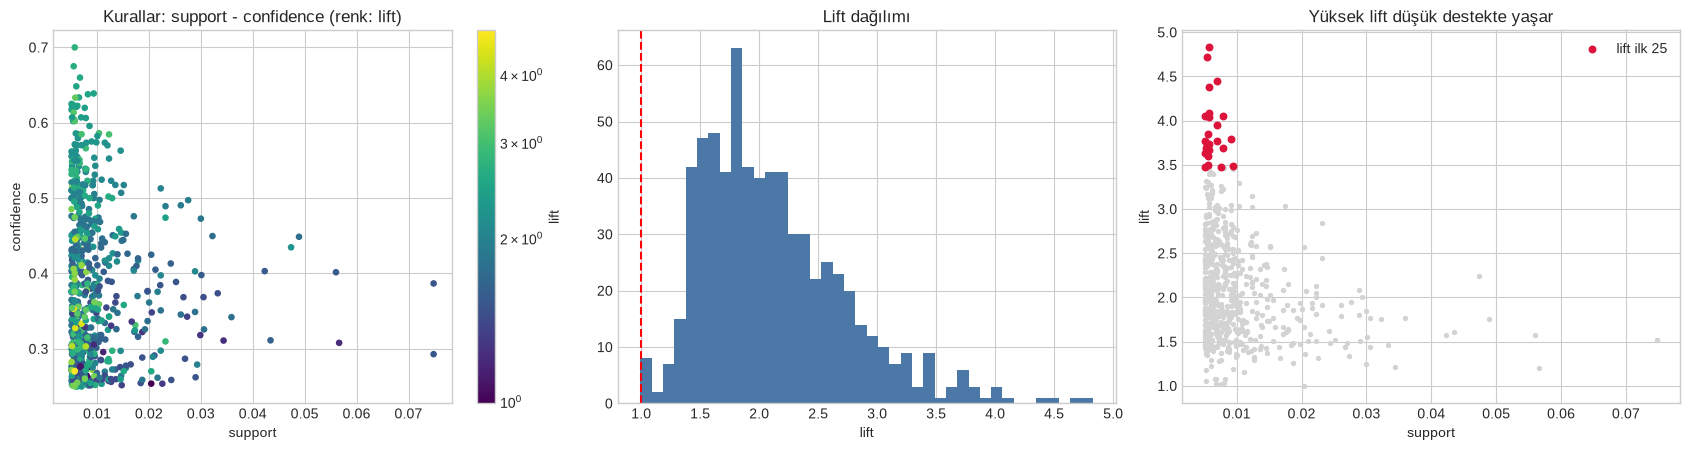

YORUM: Confidence ile lift sıralaması zayıf ilişkili (Spearman 0.27): confidence en çok 'whole milk' sonuçlu (yaygın) kuralları, lift ise nadir ve spesifik eşleşmeleri öne çıkarıyor.
       Leverage destekle güçlü bağlı (Spearman 0.75): çok satan ürünlerin kurallarını öne çıkarır; lift ise destekle ters yönlü (-0.23). Sağ grafik: en yüksek lift'li kurallar en düşük destekli olanlar.
       Lift>1 olan kural oranı: 99.9% — minconf=0.25 ile süzülen kuralların neredeyse hepsi pozitif ilişkili. Hangi ölçüyü seçtiğin, 'en iyi kural' listeni baştan değiştirir.


In [12]:
rank = R_g[['support', 'confidence', 'lift', 'leverage']].replace(np.inf, np.nan).corr(method='spearman')
print("Spearman sıra korelasyonu (kural sıralamaları):"); print(rank.round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sc = ax[0].scatter(R_g.support, R_g.confidence, c=R_g.lift, s=14, cmap='viridis', norm=plt.matplotlib.colors.LogNorm())
ax[0].set(xlabel='support', ylabel='confidence', title='Kurallar: support - confidence (renk: lift)'); plt.colorbar(sc, ax=ax[0], label='lift')
ax[1].hist(R_g.lift, bins=40, color='#4C78A8'); ax[1].axvline(1, c='r', ls='--'); ax[1].set(title='Lift dağılımı', xlabel='lift')
top = R_g.sort_values('lift', ascending=False).head(25)
ax[2].scatter(R_g.support, R_g.lift, s=8, color='lightgray'); ax[2].scatter(top.support, top.lift, s=22, color='crimson', label='lift ilk 25')
ax[2].set(title='Yüksek lift düşük destekte yaşar', xlabel='support', ylabel='lift'); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"YORUM: Confidence ile lift sıralaması zayıf ilişkili (Spearman {rank.loc['confidence','lift']:.2f}): confidence en çok 'whole milk' sonuçlu (yaygın) kuralları, lift ise nadir ve spesifik eşleşmeleri öne çıkarıyor.")
print(f"       Leverage destekle güçlü bağlı (Spearman {rank.loc['support','leverage']:.2f}): çok satan ürünlerin kurallarını öne çıkarır; lift ise destekle ters yönlü ({rank.loc['support','lift']:.2f}). Sağ grafik: en yüksek lift'li kurallar en düşük destekli olanlar.")
print(f"       Lift>1 olan kural oranı: {(R_g.lift>1).mean():.1%} — minconf=0.25 ile süzülen kuralların neredeyse hepsi pozitif ilişkili. Hangi ölçüyü seçtiğin, 'en iyi kural' listeni baştan değiştirir.")

## Adım 5 · Online Retail (UK): Ürün Aileleri

Geniş sepetli (ort. 14 ürün), mevsimsel, toptan hediyelik eşya verisi. `minsup=0.02` (en az ~300 fatura), `minconf=0.5`. Kurallar çoğunlukla **aynı ürün ailesi** içinde (aynı desenin farklı renk/boy varyantları) çıkar; bunu görmek için `lift ≥ 8` kurallarını bağlantılı bileşenlere (union-find) ayırıyoruz.

Sık küme: 587 | kural (conf>=0.5): 150 | lift>1: 100.0%

--- Lift'e göre ilk 6 ---
                                                                                kural  support  confidence    lift  leverage
                 SMALL MARSHMALLOWS PINK BOWL  =>  SMALL DOLLY MIX DESIGN ORANGE BOWL   0.0225      0.7827 22.8647    0.0215
                 SMALL DOLLY MIX DESIGN ORANGE BOWL  =>  SMALL MARSHMALLOWS PINK BOWL   0.0225      0.6582 22.8647    0.0215
          WOODEN STAR CHRISTMAS SCANDINAVIAN  =>  WOODEN HEART CHRISTMAS SCANDINAVIAN   0.0247      0.7715 22.5812    0.0237
          WOODEN HEART CHRISTMAS SCANDINAVIAN  =>  WOODEN STAR CHRISTMAS SCANDINAVIAN   0.0247      0.7244 22.5812    0.0237
   RED RETROSPOT CHARLOTTE BAG + WOODLAND CHARLOTTE BAG  =>  STRAWBERRY CHARLOTTE BAG   0.0205      0.7093 15.6944    0.0192
RED RETROSPOT CHARLOTTE BAG + WOODLAND CHARLOTTE BAG  =>  CHARLOTTE BAG PINK POLKADOT   0.0202      0.6977 15.4141    0.0189

--- Confidence'a göre ilk 5 ---
         

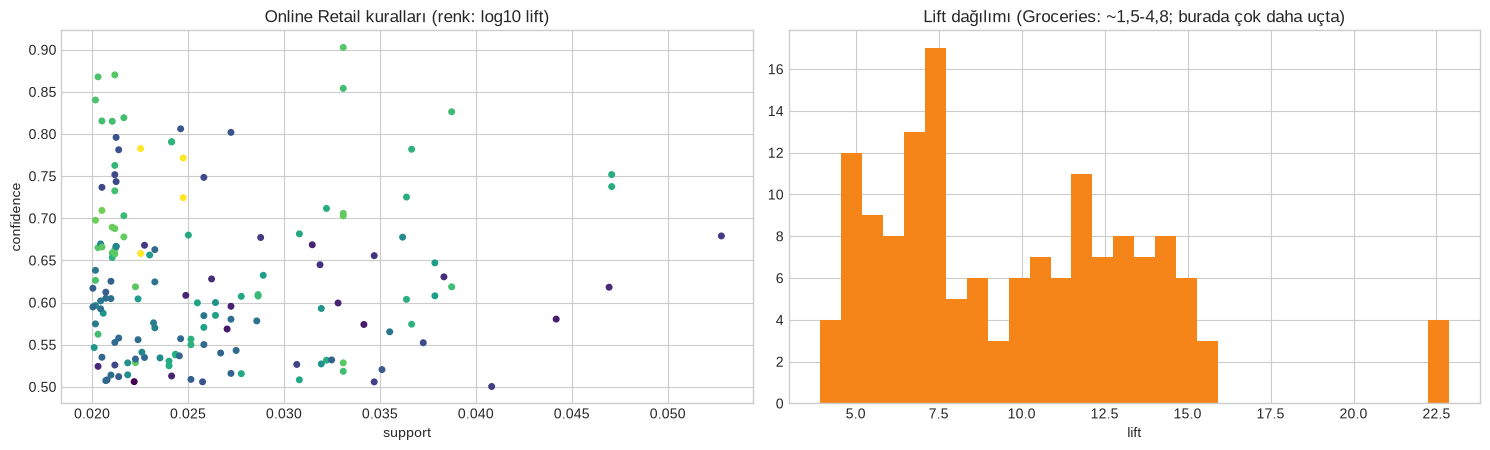

YORUM: Lift değerleri Groceries'inkinden çok yüksek (maks. 22.9): toptan müşteri aynı desenin renk/varyant setini birlikte alıyor. Kurallar 'çapraz satış keşfi'
       değil 'paket/koleksiyon' yapısını yansıtıyor — bu pratikte ürün kataloğunu aileler halinde gruplama (ve öneriyi aileler arasına yaymak) için ipucu.


In [13]:
sup_r, _ = apriori_scratch(retail, 0.02)
R_r = rules_scratch(sup_r, 0.5)
print(f"Sık küme: {len(sup_r)} | kural (conf>=0.5): {len(R_r)} | lift>1: {(R_r.lift>1).mean():.1%}")
print("\n--- Lift'e göre ilk 6 ---");       print(show_rules(R_r, 'lift', 6))
print("\n--- Confidence'a göre ilk 5 ---"); print(show_rules(R_r, 'confidence', 5))

# lift>=8 kuralların ürün-grafı: bağlantılı bileşen = ürün ailesi
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for a_, b_ in zip(R_r[R_r.lift >= 8].A, R_r[R_r.lift >= 8].B):
    members = list(a_ | b_)
    for m in members[1:]: parent[find(m)] = find(members[0])
fam = defaultdict(set)
for m in list(parent): fam[find(m)].add(m)
fams = sorted(fam.values(), key=len, reverse=True)
print(f"\nlift>=8 kurallarından {len(fams)} ürün ailesi:")
for f in fams[:6]:
    print(f"  ({len(f)} ürün)", '; '.join(sorted(f))[:150])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].scatter(R_r.support, R_r.confidence, c=np.log10(R_r.lift), s=16, cmap='viridis'); ax[0].set(xlabel='support', ylabel='confidence', title='Online Retail kuralları (renk: log10 lift)')
ax[1].hist(R_r.lift, bins=30, color='#F58518'); ax[1].set(title='Lift dağılımı (Groceries: ~1,5-4,8; burada çok daha uçta)', xlabel='lift')
plt.tight_layout(); plt.show()
print(f"YORUM: Lift değerleri Groceries'inkinden çok yüksek (maks. {R_r.lift.max():.1f}): toptan müşteri aynı desenin renk/varyant setini birlikte alıyor. Kurallar 'çapraz satış keşfi'")
print("       değil 'paket/koleksiyon' yapısını yansıtıyor — bu pratikte ürün kataloğunu aileler halinde gruplama (ve öneriyi aileler arasına yaymak) için ipucu.")

## Adım 6 · Kurallar Gelecekte de Geçerli mi? Zamana Göre Ayırma

Faturalar zamana göre sıralı (Aralık 2010 – Aralık 2011). **İlk %70'ten** kural çıkarıp (minsup 0.01, minconf 0.4), **son %30'da** her kuralın destek/confidence/lift'ini **yeniden hesaplıyoruz**. Soru: eğitimde yüksek görünen ölçü, gelecekte de yüksek mi? Hangi ölçü daha kararlı?

*Not:* bu bir "hold-out" deneyi; kural seçimi sadece eğitimde yapılıyor, test verisi hiç görülmedi.

Eğitim 10,408 fatura (2010-12-01 .. 2011-09-26), test 4,461 fatura (2011-09-26 .. 2011-12-09)
Eğitimde bulunan kural: 3083 | testte lift>1 kalan: 99.8% | testte lift>2: 99.8%

Eğitim -> test Spearman korelasyonu:
  support     0.47
  confidence  0.78
  lift        0.86
  leverage    0.45

Eğitimde ilk 40 kural (ölçüye göre) -> testteki ortalama değerler:
seçim_ölçüsü  eğitim_lift  test_lift  eğitim_conf  test_conf  test_lift_büyük_1
  confidence       13.681     16.012        0.896      0.911                1.0
        lift       30.830     34.688        0.651      0.618                1.0
    leverage        7.821     10.805        0.572      0.559                1.0
     support        7.341     10.261        0.573      0.556                1.0


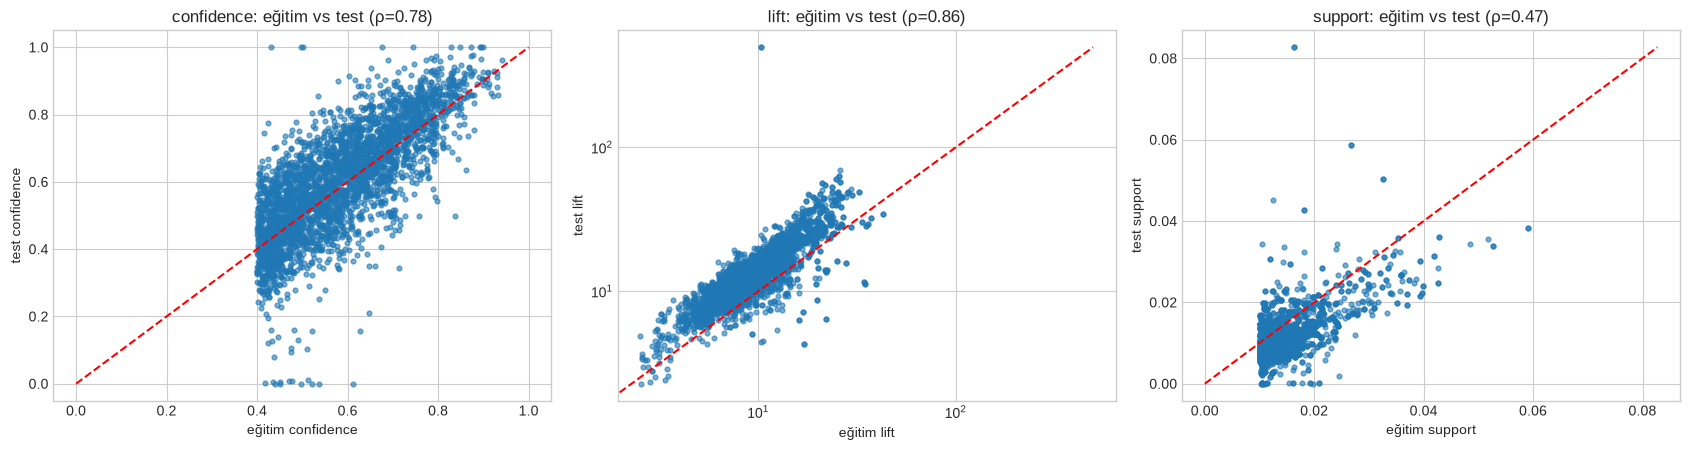

In [14]:
cut = int(0.7 * n_r)
train_r, test_r = retail[:cut], retail[cut:]
sup_tr, _ = apriori_scratch(train_r, 0.01)
R_tr = rules_scratch(sup_tr, 0.4)

# test seti bool matrisi -> herhangi bir küme için destek
vocab = {it: j for j, it in enumerate(sorted({i for t in retail for i in t}))}
Mte = np.zeros((len(test_r), len(vocab)), dtype=bool)
for r_, t in enumerate(test_r):
    Mte[r_, [vocab[i] for i in t]] = True
def sup_test(S):
    return Mte[:, [vocab[i] for i in S]].all(axis=1).mean()

R_tr = R_tr.copy()
R_tr['sup_AB_te'] = [sup_test(a | b) for a, b in zip(R_tr.A, R_tr.B)]
R_tr['sup_A_te'] = [sup_test(a) for a in R_tr.A]
R_tr['sup_B_te'] = [sup_test(b) for b in R_tr.B]
ok = (R_tr.sup_A_te > 0) & (R_tr.sup_B_te > 0)
R_tr = R_tr[ok].copy()
R_tr['conf_te'] = R_tr.sup_AB_te / R_tr.sup_A_te
R_tr['lift_te'] = R_tr.conf_te / R_tr.sup_B_te
R_tr['lev_te'] = R_tr.sup_AB_te - R_tr.sup_A_te * R_tr.sup_B_te

print(f"Eğitim {len(train_r):,} fatura ({str(retail_dates[0])[:10]} .. {str(retail_dates[cut-1])[:10]}), test {len(test_r):,} fatura ({str(retail_dates[cut])[:10]} .. {str(retail_dates[-1])[:10]})")
print(f"Eğitimde bulunan kural: {len(R_tr)} | testte lift>1 kalan: {(R_tr.lift_te>1).mean():.1%} | testte lift>2: {(R_tr.lift_te>2).mean():.1%}")
pairs = [('support', 'sup_AB_te'), ('confidence', 'conf_te'), ('lift', 'lift_te'), ('leverage', 'lev_te')]
print("\nEğitim -> test Spearman korelasyonu:")
for a_, b_ in pairs: print(f"  {a_:11s} {spearmanr(R_tr[a_], R_tr[b_])[0]:.2f}")

print("\nEğitimde ilk 40 kural (ölçüye göre) -> testteki ortalama değerler:")
rows = []
for key in ('confidence', 'lift', 'leverage', 'support'):
    top = R_tr.sort_values(key, ascending=False).head(40)
    rows.append(dict(seçim_ölçüsü=key, eğitim_lift=top.lift.mean(), test_lift=top.lift_te.mean(), eğitim_conf=top.confidence.mean(), test_conf=top.conf_te.mean(), test_lift_büyük_1=(top.lift_te > 1).mean()))
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (tr_, te_), nm in zip(ax, [('confidence', 'conf_te'), ('lift', 'lift_te'), ('support', 'sup_AB_te')], ['confidence', 'lift', 'support']):
    a.scatter(R_tr[tr_], R_tr[te_], s=12, alpha=.6); lim = [min(R_tr[tr_].min(), R_tr[te_].min()), max(R_tr[tr_].max(), R_tr[te_].max())]
    a.plot(lim, lim, 'r--'); a.set(xlabel=f'eğitim {nm}', ylabel=f'test {nm}', title=f'{nm}: eğitim vs test (ρ={spearmanr(R_tr[tr_], R_tr[te_])[0]:.2f})')
    if nm == 'lift': a.set_xscale('log'); a.set_yscale('log')
plt.tight_layout(); plt.show()

In [15]:
rho = {a_: spearmanr(R_tr[a_], R_tr[b_])[0] for a_, b_ in pairs}
top_l = R_tr.sort_values('lift', ascending=False).head(40)
print(f"YORUM: Eğitimde bulunan {len(R_tr)} kuralın %{(R_tr.lift_te>1).mean()*100:.1f}'i test döneminde de pozitif ilişkili (lift>1) - yapı kalıcı. Sıra korelasyonları: lift {rho['lift']:.2f} > confidence {rho['confidence']:.2f} > support {rho['support']:.2f} ~ leverage {rho['leverage']:.2f}.")
print("       Yani en kararlı ölçü lift/confidence; support ve leverage ise dönemden döneme fatura hacmi ve ürün karışımı (Eylül-Aralık = Noel öncesi sezon) değişince kayıyor.")
direction = 'küçüldü' if top_l.lift_te.mean() < top_l.lift.mean() else 'BÜYÜDÜ'
print(f"       Lift'e göre seçilen ilk 40 kuralın ortalama lift'i eğitimde {top_l.lift.mean():.1f}, testte {top_l.lift_te.mean():.1f} ({direction}). Bu veride beklenen 'winner's curse' küçülmesi OLMADI:")
print("       sezon etkisi (test dönemi Noel hazırlığı: müşteriler aynı koleksiyonun varyantlarını daha çok birlikte alıyor olabilir - hipotez, ayrıca doğrulanmadı) lift'i büyütmüş olabilir.")
print("       Çıkarım: zaman kayması hem yönde hem büyüklükte değişim getirir; kuralları periyodik yeniden hesaplamak gerekir. Düşük destekte küçülme çok daha sert (aşağıdaki Groceries deneyi).")

YORUM: Eğitimde bulunan 3083 kuralın %99.8'i test döneminde de pozitif ilişkili (lift>1) - yapı kalıcı. Sıra korelasyonları: lift 0.86 > confidence 0.78 > support 0.47 ~ leverage 0.45.
       Yani en kararlı ölçü lift/confidence; support ve leverage ise dönemden döneme fatura hacmi ve ürün karışımı (Eylül-Aralık = Noel öncesi sezon) değişince kayıyor.
       Lift'e göre seçilen ilk 40 kuralın ortalama lift'i eğitimde 30.8, testte 34.7 (BÜYÜDÜ). Bu veride beklenen 'winner's curse' küçülmesi OLMADI:
       sezon etkisi (test dönemi Noel hazırlığı: müşteriler aynı koleksiyonun varyantlarını daha çok birlikte alıyor olabilir - hipotez, ayrıca doğrulanmadı) lift'i büyütmüş olabilir.
       Çıkarım: zaman kayması hem yönde hem büyüklükte değişim getirir; kuralları periyodik yeniden hesaplamak gerekir. Düşük destekte küçülme çok daha sert (aşağıdaki Groceries deneyi).


### Winner's curse: düşük destekli yüksek-lift kuralları

Aynı soruyu **Groceries**'te, ama bu kez **çok düşük destekle** (`minsup=0.001`, yani eğitimde yalnızca ~7 sepet) soralım. Groceries'te zaman damgası yok, bu yüzden **rastgele** %70/%30 ayırıyoruz (bu yüzden "gelecek" değil, "görülmemiş sepetler" sınaması). Eğitimde destek kovasına göre en yüksek lift'li kurallar testte ne kadar tutuyor?

In [16]:
perm = RNG.permutation(n_g)
tr_g = [groceries[i] for i in perm[:int(.7 * n_g)]]; te_g = [groceries[i] for i in perm[int(.7 * n_g):]]
sup_trg = fpgrowth_scratch(tr_g, 0.001)
R_trg = rules_scratch(sup_trg, 0.2)
voc_g = {it: j for j, it in enumerate(sorted(item_cnt.index))}
Mg = np.zeros((len(te_g), len(voc_g)), dtype=bool)
for r_, t in enumerate(te_g): Mg[r_, [voc_g[i] for i in t]] = True
sup_te_g = lambda S: Mg[:, [voc_g[i] for i in S]].all(axis=1).mean()
R_trg = R_trg.copy()
R_trg['sAB'] = [sup_te_g(a | b) for a, b in zip(R_trg.A, R_trg.B)]
R_trg['sA'] = [sup_te_g(a) for a in R_trg.A]; R_trg['sB'] = [sup_te_g(b) for b in R_trg.B]
print(f"Eğitimde {len(R_trg):,} kural (minsup=0.001, minconf=0.2); testte A veya B hiç görünmeyen: {((R_trg.sA==0)|(R_trg.sB==0)).sum()}")
R_trg = R_trg[(R_trg.sA > 0) & (R_trg.sB > 0)].copy()
R_trg['lift_te'] = (R_trg.sAB / R_trg.sA) / R_trg.sB
R_trg['n_AB_tr'] = (R_trg.support * len(tr_g)).round().astype(int)
bins = [6, 9, 15, 30, 10**6]; labels = ['7-9 sepet', '10-15', '16-30', '>30']
R_trg['destek_kovası'] = pd.cut(R_trg.n_AB_tr, bins=bins, labels=labels)
rows = []
for lab, g_ in R_trg.groupby('destek_kovası', observed=True):
    top = g_.sort_values('lift', ascending=False).head(50)
    rows.append(dict(kova=lab, kural=len(g_), eğitim_lift_ilk50=top.lift.mean(), test_lift_ilk50=top.lift_te.mean(), testte_lift_büyük_1=(top.lift_te > 1).mean(), tüm_kuralların_test_lift_medyanı=g_.lift_te.median()))
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("YORUM: Destek kovası ne kadar düşükse eğitim lift'i ile test lift'i arasındaki fark o kadar büyük: en uç değerli kurallar çoğunlukla şans eseri öyle görünüyordu (regresyon-ortalamaya).")
print("       Kural listesinde 'çok yüksek lift'e bakarken desteğe ve testteki karşılığa bakılmazsa yanlış bir güven doğar; pratikte minimum destek (örn. >=30-50 sepet) ve hold-out doğrulaması şart.")

Eğitimde 34,393 kural (minsup=0.001, minconf=0.2); testte A veya B hiç görünmeyen: 413
     kova  kural  eğitim_lift_ilk50  test_lift_ilk50  testte_lift_büyük_1  tüm_kuralların_test_lift_medyanı
7-9 sepet  19858              48.25             4.81                 0.34                              2.36
    10-15   9313              20.65             7.32                 0.62                              2.37
    16-30   3600               8.86             4.30                 0.86                              2.21
      >30   1209               4.64             3.21                 1.00                              1.92
YORUM: Destek kovası ne kadar düşükse eğitim lift'i ile test lift'i arasındaki fark o kadar büyük: en uç değerli kurallar çoğunlukla şans eseri öyle görünüyordu (regresyon-ortalamaya).
       Kural listesinde 'çok yüksek lift'e bakarken desteğe ve testteki karşılığa bakılmazsa yanlış bir güven doğar; pratikte minimum destek (örn. >=30-50 sepet) ve hold-out doğrulaması şa

## Adım 7 · Öneri Deneyi: Kurallar Popülerliği Geçer mi?

Kural tabanlı öneri: bir sepet için, **antecedent'i sepetin alt kümesi olan** ("ateşlenen") kuralların sonuçlarını ürün düzeyinde topla, bir **skor** (confidence, lift...) ile sırala, sepette zaten olmayan ilk $k$ ürünü öner.

**Değerlendirme (hit-rate@k):** Test sepetlerinde (≥2 ürünlü) her ürünü sırayla sakla, kalanlardan öner, saklanan ürün ilk $k$'da mı? **Taban çizgisi:** her zaman en popüler $k$ ürünü (sepette olmayanlardan) öner. Kural yeterince tetiklenmezse kalan yerleri popülerlikle doldururuz (eşit koşullar).

Kurallar eğitim (%70) setinden; `minsup=0.002`, `minconf=0.05`, tek-ürünlü sonuç. Matris-çarpımı ile hepsi tek seferde hesaplanır.

Kural sayısı: 11,183 | değerlendirme örneği (sakla-tahmin et): 12,259


                         hit@1   hit@3   hit@5  hit@10
popülerlik              0.0830  0.1857  0.2599  0.3796
kural: confidence       0.0868  0.1945  0.2702  0.3929
kural: lift             0.0227  0.0600  0.0973  0.1915
kural: leverage         0.0793  0.1855  0.2477  0.3593
kural: conf (lift>1.5)  0.0874  0.1884  0.2578  0.3764

En az bir kuralın ateşlendiği örnek oranı (confidence kuralları): 99.7%


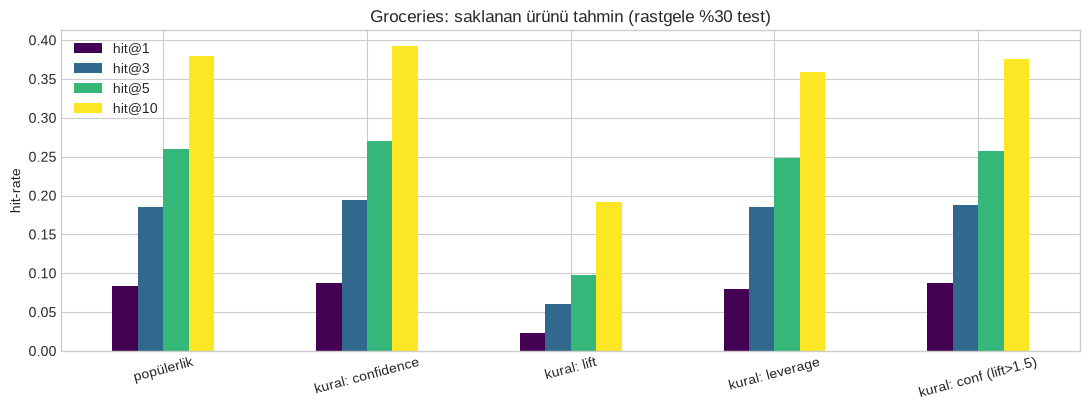

In [17]:
tr_g2 = tr_g                                                # Adım 6'daki aynı rastgele bölünme (tohumlu)
sup_t = fpgrowth_scratch(tr_g2, 0.002)
R_rec = rules_scratch(sup_t, 0.05)
R_rec = R_rec[R_rec.B.map(len) == 1].reset_index(drop=True)
items_g = sorted(voc_g, key=voc_g.get); m_g = len(items_g)
A_mat = np.zeros((len(R_rec), m_g), dtype=np.float32)
for r_, a in enumerate(R_rec.A): A_mat[r_, [voc_g[i] for i in a]] = 1
A_len = A_mat.sum(1); cons = np.array([voc_g[next(iter(b))] for b in R_rec.B])
pop_order = [voc_g[i] for i in pd.Series([i for t in tr_g2 for i in t]).value_counts().index]   # eğitim popülerliği

# test örnekleri: (kalan sepet, saklanan ürün)
rest_rows, held = [], []
for t in te_g:
    if len(t) < 2: continue
    v = np.zeros(m_g, dtype=np.float32); v[[voc_g[i] for i in t]] = 1
    for i in t:
        r_ = v.copy(); r_[voc_g[i]] = 0; rest_rows.append(r_); held.append(voc_g[i])
Rest = np.vstack(rest_rows); held = np.array(held)
print(f"Kural sayısı: {len(R_rec):,} | değerlendirme örneği (sakla-tahmin et): {len(held):,}")

def topk_from_scores(S, Rest, k):
    S = np.where(Rest > 0, -np.inf, S)                      # sepetteki ürünler önerilmez
    return np.argsort(-S, axis=1, kind='stable')[:, :k]

def rule_scores(key_vals, Rest, fill_pop=True):
    fire = (Rest @ A_mat.T) == A_len[None, :]               # antecedent sepetin alt kümesi mi?
    S = np.full((Rest.shape[0], m_g), -1.0, dtype=np.float32)
    for c in range(m_g):
        cols = np.where(cons == c)[0]
        if cols.size: S[:, c] = np.where(fire[:, cols], key_vals[cols][None, :], -1.0).max(1)
    covered = (S > -1).any(1)
    if fill_pop:                                            # kural yoksa: popülerlik (küçük ek skor, sıralamayı bozmadan)
        S = np.where(S > -1, S + 10.0, 0.0) + np.array([1.0 / (1 + pop_order.index(c)) for c in range(m_g)], dtype=np.float32)[None, :] * 1e-3
    return S, covered

def hit_at(S, k):
    top = topk_from_scores(S, Rest, k)
    return (top == held[:, None]).any(1).mean()

pop_scores = np.tile(np.array([1.0 / (1 + pop_order.index(c)) for c in range(m_g)], dtype=np.float32), (Rest.shape[0], 1))
res = {'popülerlik': pop_scores}
cover = {}
for key in ('confidence', 'lift', 'leverage'):
    res[f'kural: {key}'], cover[key] = rule_scores(R_rec[key].to_numpy(dtype=np.float32), Rest)
# hibrit: sadece lift>1.5 olan kurallar, confidence ile sırala
mask = (R_rec.lift.to_numpy() > 1.5)
kv = np.where(mask, R_rec.confidence.to_numpy(), -1.0).astype(np.float32)
res['kural: conf (lift>1.5)'], cover['hybrid'] = rule_scores(np.where(mask, R_rec.confidence.to_numpy(), 0.0).astype(np.float32), Rest)

tab = pd.DataFrame({name: [hit_at(S, k) for k in (1, 3, 5, 10)] for name, S in res.items()}, index=['hit@1', 'hit@3', 'hit@5', 'hit@10']).T
print(tab.round(4).to_string())
print(f"\nEn az bir kuralın ateşlendiği örnek oranı (confidence kuralları): {cover['confidence'].mean():.1%}")
tab.plot(kind='bar', figsize=(11, 4.2), rot=15, colormap='viridis'); plt.ylabel('hit-rate'); plt.title('Groceries: saklanan ürünü tahmin (rastgele %30 test)'); plt.tight_layout(); plt.show()

In [18]:
pop5, con5 = tab.loc['popülerlik', 'hit@5'], tab.loc['kural: confidence', 'hit@5']
se = np.sqrt(pop5 * (1 - pop5) / len(held))
print(f"YORUM: hit@5 - popülerlik {pop5:.3f}, kural(confidence) {con5:.3f} (+{(con5-pop5)*100:.1f} puan), kural(leverage) {tab.loc['kural: leverage','hit@5']:.3f}, kural(lift) {tab.loc['kural: lift','hit@5']:.3f}.")
print(f"       Confidence ile sıralayan kural tabanlı öneri popülerliği yalnızca ~{(con5-pop5)*100:.1f} puan geçiyor; tek bir oranın standart hatası ~{se*100:.1f} puan, yani kanıt zayıf (aynı örnekler üzerinde eşleştirilmiş fark daha dar olsa da bunu burada test etmedik).")
print("       Neden? Groceries sepetleri küçük (ort. 4,4 ürün) ve alışveriş 'süt/sebze/ekmek' gibi popüler ürünlerle dolu; sepet bağlamı az bilgi taşıyor.")
print("       Lift ile sıralamak ise ciddi zarar veriyor: lift nadir ürünleri öne çıkarır, ama nadir bir ürünün 'saklanan ürün' olma olasılığı düşüktür. 'İlginç kural' ile 'iyi öneri' farklı hedeflerdir.")
print("       Not: rastgele bölünme ve yalnızca sepet içeriği kullanıldı; kullanıcı geçmişi, fiyat, mevsim yok. Büyük sistemlerde bunun yerini matris/gömme modelleri alır (bkz. 23).")

YORUM: hit@5 - popülerlik 0.260, kural(confidence) 0.270 (+1.0 puan), kural(leverage) 0.248, kural(lift) 0.097.
       Confidence ile sıralayan kural tabanlı öneri popülerliği yalnızca ~1.0 puan geçiyor; tek bir oranın standart hatası ~0.4 puan, yani kanıt zayıf (aynı örnekler üzerinde eşleştirilmiş fark daha dar olsa da bunu burada test etmedik).
       Neden? Groceries sepetleri küçük (ort. 4,4 ürün) ve alışveriş 'süt/sebze/ekmek' gibi popüler ürünlerle dolu; sepet bağlamı az bilgi taşıyor.
       Lift ile sıralamak ise ciddi zarar veriyor: lift nadir ürünleri öne çıkarır, ama nadir bir ürünün 'saklanan ürün' olma olasılığı düşüktür. 'İlginç kural' ile 'iyi öneri' farklı hedeflerdir.
       Not: rastgele bölünme ve yalnızca sepet içeriği kullanıldı; kullanıcı geçmişi, fiyat, mevsim yok. Büyük sistemlerde bunun yerini matris/gömme modelleri alır (bkz. 23).


## Adım 8 · Mushroom: Yoğun Veri, Kapalı Kümeler ve Kural Patlaması

Her mantar bir "sepet": 22 kategorik özelliğin her biri bir **öğe** (`odor=n`, `gill-size=b`, ...) ve ayrıca `class=e` (yenebilir) / `class=p` (zehirli). Market verisinin tersine bu veri **yoğun**: her mantarda tam 21 özellik öğesi + 1 sınıf öğesi var (22 özellikten sabit olan `veil-type` çıkarıldı), öğeler birbiriyle çok korelidir. `stalk-root` değerlerinin %30,5'i eksik (`?`); eksikliği ayrı bir kategori (`stalk-root=?`) olarak tutuyoruz.

Önce destek eşiğini düşürürken sık küme sayısının patlamasını, sonra **kapalı / maksimal** kümelerin ne kadar küçük bir özet verdiğini görelim.

In [19]:
mush = pd.read_csv('data/mushrooms.csv').drop(columns=['veil-type'])
tx_m = [[f'{c}={v}' for c, v in zip(mush.columns, row)] for row in mush.values]
n_m = len(tx_m)
print(f"{n_m:,} mantar | {mush.shape[1]-1} özellik (veil-type çıkarıldı) | farklı öğe: {len({i for t in tx_m for i in t})} | yenebilir: {(mush['class']=='e').mean():.1%}")

rows = []
for ms in (0.4, 0.3, 0.2, 0.15, 0.1):
    t0 = time.perf_counter(); f_ = fpgrowth_scratch(tx_m, ms); rows.append(dict(minsup=ms, sık_küme=len(f_), süre_s=time.perf_counter() - t0, maks_boyut=max(len(k) for k in f_)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

f_m = fpgrowth_scratch(tx_m, 0.2)
cnt_m = {S: round(s * n_m) for S, s in f_m.items()}
by_cnt = defaultdict(set)
for S, c in cnt_m.items(): by_cnt[c].add(S)
closed = set()
for c, Ss in by_cnt.items():                                # kapalı: aynı sayımda +1 öğeli üst küme yok (anti-monotonluk yeter)
    nonclosed = {frozenset(T - {x}) for T in Ss for x in T} & Ss
    closed |= Ss - nonclosed
sets_by_len = defaultdict(set)
for S in f_m: sets_by_len[len(S)].add(S)
maximal = {S for S in f_m if not any((S | {x}) in f_m for x in {y for T in sets_by_len[len(S) + 1] for y in T - S})}
print(f"\nminsup=0.2: sık küme {len(f_m):,} -> kapalı {len(closed):,} ({len(closed)/len(f_m):.1%}) -> maksimal {len(maximal):,} ({len(maximal)/len(f_m):.2%})")

# kapalı kümelerden tüm desteklerin kayıpsız geri kurulumu: S'nin desteği = onu içeren en küçük kapalı üst kümenin desteği
closed_list = sorted(closed, key=len)
rec_ok = all(max(cnt_m[C] for C in closed_list if S <= C) == cnt_m[S] for S in list(f_m)[:3000])
print("Kapalı kümelerden destek geri kurulumu (ilk 3000 sık küme için tutarlı mı?):", rec_ok)

8,124 mantar | 21 özellik (veil-type çıkarıldı) | farklı öğe: 118 | yenebilir: 51.8%


 minsup  sık_küme  süre_s  maks_boyut
   0.40       282    0.04           6
   0.30      1367    0.06           8
   0.20     26791    0.21          14
   0.15     49287    0.63          14
   0.10    287215    2.19          15



minsup=0.2: sık küme 26,791 -> kapalı 1,196 (4.5%) -> maksimal 158 (0.59%)
Kapalı kümelerden destek geri kurulumu (ilk 3000 sık küme için tutarlı mı?): True


In [20]:
print("YORUM: Market verisinden farklı olarak burada küçük eşik düşüşü bile sık küme sayısını on binlerce/yüz binlerce yapıyor (yoğun veri: her mantarda 21 özellik + sınıf öğesi var).")
print(f"       Kapalı kümeler tüm sık kümelerin yalnızca %{len(closed)/len(f_m)*100:.1f}'i ama hiçbir destek bilgisi kaybolmuyor; maksimal kümeler daha da küçük (%{len(maximal)/len(f_m)*100:.2f}) ama destekleri geri kuramıyoruz.")
print("       Yoğun/uzun desenli veride 'tüm sık kümeleri çıkar' yerine kapalı küme algoritmaları (CHARM, CLOSET, LCM) kullanılır.")

YORUM: Market verisinden farklı olarak burada küçük eşik düşüşü bile sık küme sayısını on binlerce/yüz binlerce yapıyor (yoğun veri: her mantarda 21 özellik + sınıf öğesi var).
       Kapalı kümeler tüm sık kümelerin yalnızca %4.5'i ama hiçbir destek bilgisi kaybolmuyor; maksimal kümeler daha da küçük (%0.59) ama destekleri geri kuramıyoruz.
       Yoğun/uzun desenli veride 'tüm sık kümeleri çıkar' yerine kapalı küme algoritmaları (CHARM, CLOSET, LCM) kullanılır.


### Özellik ⇒ Sınıf kuralları, gereksiz kurallar ve minimal antecedent

Sonuç `class=e` veya `class=p` olan kuralları çıkaralım (`minsup=0.1`). Kuralların büyük kısmı confidence=1'dir; ama bunların çoğu **gereksiz**: `odor=n ∧ ring-number=o ⇒ class=e` zaten kesin ise ona herhangi bir özellik eklemek yeni bilgi vermez. **Minimal antecedent:** aynı sonuca, aynı veya daha yüksek confidence ile varan bir alt-küme kuralı varsa kuralı at.

In [21]:
f_c = fpgrowth_scratch(tx_m, 0.1)
rows = []
for Z, s in f_c.items():
    B = frozenset(i for i in Z if i.startswith('class='))
    if len(B) == 1 and len(Z) > 1:
        A = Z - B; rows.append((A, next(iter(B)), s, s / f_c[A], s / f_c[A] / f_c[B]))
R_m = pd.DataFrame(rows, columns=['A', 'cls', 'support', 'confidence', 'lift'])
R_m['k'] = R_m.A.map(len)
print(f"minsup=0.1: sık küme {len(f_c):,} | sınıf-sonuçlu kural {len(R_m):,} | confidence=1 olan {int((R_m.confidence==1).sum()):,} ({(R_m.confidence==1).mean():.1%})")

def minimal_rules(R, conf_min):
    """Aynı sonuç için, antecedent'inin bir alt kümesi zaten >= conf_min olan kuralı gereksiz sayar."""
    out = []
    for cls_, g_ in R[R.confidence >= conf_min].groupby('cls'):
        kept = []
        for r in g_.sort_values('k').itertuples():
            if not any(m <= r.A for m in kept): kept.append(r.A); out.append(r)
    return pd.DataFrame(out)
R_min = minimal_rules(R_m, 1.0)
print(f"Minimal-antecedent confidence=1 kuralı: {len(R_min):,}  (gereksiz oran: {1-len(R_min)/(R_m.confidence==1).sum():.1%})")
R_min = R_min.assign(kural=R_min.A.map(lambda a: ' & '.join(sorted(a))) + '  =>  ' + R_min.cls)
print("\nEn yüksek destekli minimal kurallar:")
print(R_min.sort_values('support', ascending=False).head(8)[['kural', 'support', 'lift', 'k']].round(3).to_string(index=False))
print("\nTek özellikli (k=1) en iyi kurallar (confidence):")
r1 = R_m[R_m.k == 1].assign(kural=lambda d: d.A.map(lambda a: next(iter(a))) + '  =>  ' + d.cls).sort_values(['confidence', 'support'], ascending=False)
print(r1.head(8)[['kural', 'support', 'confidence']].round(3).to_string(index=False))

minsup=0.1: sık küme 287,215 | sınıf-sonuçlu kural 140,218 | confidence=1 olan 117,258 (83.6%)


Minimal-antecedent confidence=1 kuralı: 242  (gereksiz oran: 99.8%)

En yüksek destekli minimal kurallar:
                                                                            kural  support  lift  k
                                gill-size=b & odor=n & ring-number=o  =>  class=e    0.331 1.931  3
                                              odor=n & stalk-shape=t  =>  class=e    0.307 1.931  2
                         gill-spacing=c & stalk-surface-above-ring=k  =>  class=p    0.274 2.075  2
                          ring-number=o & stalk-surface-above-ring=k  =>  class=p    0.270 2.075  2
                                                              odor=f  =>  class=p    0.266 2.075  1
                          ring-number=o & stalk-surface-below-ring=k  =>  class=p    0.266 2.075  2
                         gill-spacing=c & stalk-surface-below-ring=k  =>  class=p    0.266 2.075  2
gill-spacing=c & odor=n & ring-number=o & stalk-surface-above-ring=s  =>  class=e    0.254 1.9

In [22]:
# eğitim/test: kural kümesiyle sınıflandırma (zehirliyi yenebilir sanmak = tehlikeli hata)
perm_m = RNG.permutation(n_m); ntr = int(.7 * n_m)
tr_m = [tx_m[i] for i in perm_m[:ntr]]; te_m = [tx_m[i] for i in perm_m[ntr:]]
f_tr = fpgrowth_scratch(tr_m, 0.1)
rows = []
for Z, s in f_tr.items():
    B = frozenset(i for i in Z if i.startswith('class='))
    if len(B) == 1 and len(Z) > 1:
        A = Z - B; rows.append((A, next(iter(B)), s, s / f_tr[A], s / f_tr[A] / f_tr[B]))
Rm_tr = pd.DataFrame(rows, columns=['A', 'cls', 'support', 'confidence', 'lift']); Rm_tr['k'] = Rm_tr.A.map(len)
rules_tr = minimal_rules(Rm_tr, 0.99)                       # eğitimde >=%99 kesinlikteki minimal kurallar
fires = {c: [a for a, cl in zip(rules_tr.A, rules_tr.cls) if cl == c] for c in ('class=e', 'class=p')}
pred, truth = [], []
for t in te_m:
    st = set(t); truth.append('class=e' if 'class=e' in st else 'class=p')
    pe = any(a <= st for a in fires['class=e']); pp = any(a <= st for a in fires['class=p'])
    pred.append('e' if pe and not pp else 'p' if pp and not pe else '?' if not pe and not pp else 'çakışma')
ct = pd.crosstab(pd.Series(truth, name='gerçek'), pd.Series(pred, name='kural tahmini'))
print(f"Eğitimde {len(rules_tr)} minimal kural (conf>=0.99, supp>=0.1) | test {len(te_m):,} mantar"); print(ct.to_string())
covd = np.array(pred) != '?'
acc = np.mean([(p == 'e') == (t == 'class=e') for p, t in zip(np.array(pred)[covd], np.array(truth)[covd]) if p in ('e', 'p')])
dangerous = sum(1 for p, t in zip(pred, truth) if p == 'e' and t == 'class=p')
print(f"\nKapsama (kural tahmini yapılan): {covd.mean():.1%} | kapsanan tahminlerde doğruluk: {acc:.3f} | 'yenebilir' deyip zehirli çıkan: {dangerous}")

# tek özellik taban çizgisi (OneR): her özellik için değer -> çoğunluk sınıfı, en iyisini eğitimde seç
tr_df = mush.iloc[perm_m[:ntr]]; te_df = mush.iloc[perm_m[ntr:]]
best_col, best_acc = None, 0
for c in mush.columns[1:]:
    maj_c = tr_df.groupby(c)['class'].agg(lambda s: s.value_counts().idxmax())
    tr_acc = (tr_df[c].map(maj_c) == tr_df['class']).mean()          # seçim yalnızca EĞİTİM doğruluğuyla
    if tr_acc > best_acc: best_col, best_acc = c, tr_acc
maj = tr_df.groupby(best_col)['class'].agg(lambda s: s.value_counts().idxmax())
te_acc_oner = (te_df[best_col].map(maj) == te_df['class']).mean()
poison_as_edible = ((te_df[best_col].map(maj) == 'e') & (te_df['class'] == 'p')).sum()
print(f"OneR (eğitimde en iyi tek özellik = {best_col}): test doğruluğu {te_acc_oner:.3f}, zehirliyi yenebilir sanan: {poison_as_edible}")

Eğitimde 230 minimal kural (conf>=0.99, supp>=0.1) | test 2,438 mantar
kural tahmini   ?     e     p  çakışma
gerçek                                
class=e         0  1195     0        5
class=p        72     2  1148       16

Kapsama (kural tahmini yapılan): 97.0% | kapsanan tahminlerde doğruluk: 0.999 | 'yenebilir' deyip zehirli çıkan: 2
OneR (eğitimde en iyi tek özellik = odor): test doğruluğu 0.981, zehirliyi yenebilir sanan: 46


In [23]:
n_conf1 = int((R_m.confidence == 1).sum())
print(f"YORUM: confidence=1 olan {n_conf1:,} kural minimal antecedent'e inince {len(R_min)} kural kalıyor: yani kuralların %{(1-len(R_min)/n_conf1)*100:.1f}'i yeni bilgi taşımayan uzantılar. Kural listeleri bu budamadan geçmeden okunamaz.")
print("       Tek özellik (koku) bile çok güçlü: `odor=f => zehirli` ve `gill-color=b => zehirli` eğitimdeki tüm veride %100; `odor=n => yenebilir` %96,6.")
n_unk = int((np.array(pred) == '?').sum()); n_conf = int((np.array(pred) == 'çakışma').sum())
print(f"       Kural kümesi test mantarlarının %{covd.mean()*100:.0f}'ini kapsıyor, kapsadığı tek-yönlü tahminlerde doğruluk {acc:.3f}; {n_unk} mantar için 'bilmiyorum' ('?'), {n_conf} için iki sınıf kuralı birlikte ateşlendi (çakışma) deyip çekimser kalıyor.")
print(f"       Kıyas: OneR (`{best_col}`) doğruluk {te_acc_oner:.3f} ama her mantar için karar veriyor ve zehirliyi yenebilir sanan {poison_as_edible}; kural kümesinde bu sayı {dangerous}. Kuralların değeri 'çekimser kalabilmesi'.")
print("       Uyarı: bu bir mantar yeme rehberi değildir; confidence=1 eğitimde kesinlik demek, testte (ve gerçekte) sıfır garanti değildir.")

YORUM: confidence=1 olan 117,258 kural minimal antecedent'e inince 242 kural kalıyor: yani kuralların %99.8'i yeni bilgi taşımayan uzantılar. Kural listeleri bu budamadan geçmeden okunamaz.
       Tek özellik (koku) bile çok güçlü: `odor=f => zehirli` ve `gill-color=b => zehirli` eğitimdeki tüm veride %100; `odor=n => yenebilir` %96,6.
       Kural kümesi test mantarlarının %97'ini kapsıyor, kapsadığı tek-yönlü tahminlerde doğruluk 0.999; 72 mantar için 'bilmiyorum' ('?'), 21 için iki sınıf kuralı birlikte ateşlendi (çakışma) deyip çekimser kalıyor.
       Kıyas: OneR (`odor`) doğruluk 0.981 ama her mantar için karar veriyor ve zehirliyi yenebilir sanan 46; kural kümesinde bu sayı 2. Kuralların değeri 'çekimser kalabilmesi'.
       Uyarı: bu bir mantar yeme rehberi değildir; confidence=1 eğitimde kesinlik demek, testte (ve gerçekte) sıfır garanti değildir.


## Adım 9 · Null-Değişmezlik: Lift mi, Kulczynski mi?

Han–Kamber'in kahve–süt örneğinden esinlenen tablo (sayılar değiştirildi): kahve ($c$) ve süt ($m$) birlikte alınan: $mc=10000$, $m\bar c=1000$, $\bar m c=3000$, $\bar m\bar c=100000$ fiş. **Hiçbirini içermeyen** ("null") fişlerin sayısı $\bar m\bar c$'yi değiştirirsek $m$–$c$ ilişkisi aynı kalmalı; ama lift değişir. Kulczynski $\tfrac12\big(P(c|m)+P(m|c)\big)$ ve imbalance ratio $\mathrm{IR}=\frac{|s(m)-s(c)|}{s(m)+s(c)-s(mc)}$ **null-değişmezdir**.

In [24]:
def two_by_two(mc, m_c, mc_, nn):
    n = mc + m_c + mc_ + nn; sm, sc, smc = (mc + m_c) / n, (mc + mc_) / n, mc / n
    return dict(null_fiş=nn, lift=smc / (sm * sc), kulczynski=.5 * (smc / sm + smc / sc), IR=abs(sm - sc) / (sm + sc - smc), P_c_given_m=smc / sm)
tbl = pd.DataFrame([two_by_two(10000, 1000, 3000, nn) for nn in (100, 1000, 10000, 100000, 1000000)])
print("Aynı m-c ilişkisi, null fiş sayısı değişirken:"); print(tbl.round(3).to_string(index=False))

# gerçek veri: Groceries'in en yüksek lift'li tekli kuralları; null sepet ekleyince lift şişer, Kulczynski sabit
R1 = R_g[(R_g.A.map(len) == 1) & (R_g.B.map(len) == 1)].copy()
R1['kulc'] = .5 * (R1.confidence + R1.support / R1.sup_B)
def with_nulls(R, extra):
    n2 = n_g + extra; return (R.support * n_g / n2) / ((R.sup_A * n_g / n2) * (R.sup_B * n_g / n2))
for extra in (0, 20000, 100000):
    R1[f'lift_+{extra}'] = with_nulls(R1, extra)
top = R1.sort_values('lift', ascending=False).head(6).copy()
top['kural'] = top.A.map(fmt_set) + ' => ' + top.B.map(fmt_set)
print("\nGroceries: tekli kurallar - null sepet eklenince lift'in değişimi (Kulczynski değişmez):")
print(top[['kural', 'lift_+0', 'lift_+20000', 'lift_+100000', 'kulc']].round(2).to_string(index=False))
print(f"\nLift sıralaması null eklemeyle değişir mi? Spearman = {spearmanr(R1['lift_+0'], R1['lift_+100000'])[0]:.4f} (monoton dönüşüm, sıra aynı) - ama MUTLAK lift değeri ve '>2 olanlar' kümesi değişir:")
print(f"  lift>2 olan tekli kural: +0 -> {(R1['lift_+0']>2).sum()}, +20000 -> {(R1['lift_+20000']>2).sum()}, +100000 -> {(R1['lift_+100000']>2).sum()}")
print("YORUM: İlişki aynı kaldı ama lift 'eşik' olarak kullanılırsa kural kümesi null işlem sayısına bağlı değişiyor; Kulczynski/IR bu yüzden ilgisiz sepetlerin çok olduğu büyük veride daha güvenli bir ölçüdür.")
print("       Tek bir ölçüye güvenme: pratikte support (yeterli kanıt) + Kulczynski/confidence (güç) + lift/leverage (bağımsızlıktan sapma) birlikte raporlanır.")

Aynı m-c ilişkisi, null fiş sayısı değişirken:
 null_fiş   lift  kulczynski    IR  P_c_given_m
      100  0.986       0.839 0.143        0.909
     1000  1.049       0.839 0.143        0.909
    10000  1.678       0.839 0.143        0.909
   100000  7.972       0.839 0.143        0.909
  1000000 70.909       0.839 0.143        0.909

Groceries: tekli kurallar - null sepet eklenince lift'in değişimi (Kulczynski değişmez):
                        kural  lift_+0  lift_+20000  lift_+100000  kulc
     herbs => root vegetables     3.96        12.00         44.19  0.25
berries => whipped/sour cream     3.80        11.52         42.40  0.20
     sliced cheese => sausage     3.05         9.24         34.03  0.18
      beef => root vegetables     3.04         9.22         33.95  0.25
    onions => root vegetables     2.80         8.49         31.24  0.20
     grapes => tropical fruit     2.60         7.88         29.03  0.17

Lift sıralaması null eklemeyle değişir mi? Spearman = 1.0000 (monoton 

# 📊 R Uygulaması

Birliktelik kuralları R'da **`arules`** paketinin ana işidir (Hahsler ve ark.; `apriori`, `eclat`, `interestMeasure`, `is.closed`, `is.maximal`...). Proje kararı gereği
(bkz. [[notebook_style_convention]]) R bölümünü kısa tutuyoruz: önce Python tarafında **referans sayıları** yazdırıyoruz, ardından 1 hücre `arules` ile aynı eşikleri çalıştırıp karşılaştırıyoruz.

In [25]:
# Referans sayılar (Python, Groceries, minsup=0.005, minconf=0.25) — R çıktısıyla karşılaştırmak için
cl_ref = {S: round(s * n_g) for S, s in sup_g.items()}
by_c = defaultdict(set)
for S, c in cl_ref.items(): by_c[c].add(S)
closed_g = set()
for c, Ss in by_c.items(): closed_g |= Ss - ({frozenset(T - {x}) for T in Ss for x in T} & Ss)
lens = defaultdict(set)
for S in sup_g: lens[len(S)].add(S)
maximal_g = {S for S in sup_g if not any((S | {x}) in sup_g for x in {y for T in lens[len(S) + 1] for y in T - S})}
print(f"Python referansı: sık küme {len(sup_g)} (tek ürünler dahil) | kapalı {len(closed_g)} | maksimal {len(maximal_g)} | kural (conf>=0.25) {len(R_g)}")
print("R'da (arules) aynı eşiklerde aynı sayıların çıkması beklenir; `apriori(..., minlen=1)` ile tek ürünler dahil sık küme sayısı da karşılaştırılabilir.")
cardinality_ref = pd.Series({k: v for k, v in zip(*np.unique([len(S) for S in sup_g], return_counts=True))})
print("Kümelerin boyuta göre sayısı:", cardinality_ref.to_dict())

Python referansı: sık küme 1000 (tek ürünler dahil) | kapalı 1000 | maksimal 707 | kural (conf>=0.25) 673
R'da (arules) aynı eşiklerde aynı sayıların çıkması beklenir; `apriori(..., minlen=1)` ile tek ürünler dahil sık küme sayısı da karşılaştırılabilir.
Kümelerin boyuta göre sayısı: {1: 120, 2: 604, 3: 264, 4: 12}


In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R -w 900 -h 450
# install.packages("arules")  # ilk çalıştırmada gerekir
library(arules)
tr <- read.transactions("data/groceries.csv", format = "basket", sep = ",")
cat("sepet:", length(tr), "| ürün:", dim(tr)[2], "| ortalama sepet:", round(mean(size(tr)), 2), "\n")

rules <- apriori(tr, parameter = list(supp = 0.005, conf = 0.25, minlen = 2, target = "rules"))
cat("kural sayısı (supp>=0.005, conf>=0.25):", length(rules), "\n")
inspect(head(sort(rules, by = "lift"), 5))

fs <- eclat(tr, parameter = list(supp = 0.005, minlen = 1, maxlen = 10))
cat("Eclat sık küme:", length(fs), "| kapalı:", sum(is.closed(fs)), "| maksimal:", sum(is.maximal(fs)), "\n")

q <- quality(rules)
q$kulczynski <- interestMeasure(rules, "kulczynski", tr)            # null-değişmez ölçü
cat("lift ile Kulczynski sıra korelasyonu (Spearman):", round(cor(q$lift, q$kulczynski, method = "spearman"), 2), "\n")
plot(q$support, q$confidence, pch = 19, cex = .6, col = rgb(0.2, 0.4, 0.8, 0.5), xlab = "support", ylab = "confidence", main = "R arules: Groceries kuralları")

# 🗄️ SQL Uygulaması (DuckDB)

Birliktelik analizi veri ambarında **kendine-birleştirme (self-join)** ile yapılır: sepet tablosu `basket(tid, item)`; sayım = `COUNT(*)`, destek = sayım / sepet sayısı.
Proje kararı gereği (bkz. [[notebook_style_convention]]) iki kısa hücre:

1. **İkili kurallar** $a\Rightarrow b$: ürün sayımları + çift sayımı (`JOIN ... ON a.tid = b.tid AND a.item <> b.item`) → support, confidence, lift.
2. **{a1, a2} ⇒ c kuralları:** üçlü self-join (`a1.item < a2.item`, `c ∉ {a1, a2}`) — Apriori'nin 3'lü aşamasının SQL karşılığı. Python sonuçlarıyla birebir karşılaştırıyoruz.

In [28]:
import duckdb
con = duckdb.connect()
basket = pd.DataFrame([(k, i) for k, t in enumerate(groceries) for i in t], columns=['tid', 'item'])
con.register('basket', basket)

# --- SQL-1: ikili kurallar (support >= .005, confidence >= .25) ---
pairs_sql = con.execute("""
WITH n AS (SELECT COUNT(DISTINCT tid) AS n FROM basket),
ic AS (SELECT item, COUNT(*) AS c FROM basket GROUP BY item),
pc AS (
    SELECT a.item AS a, b.item AS b, COUNT(*) AS c
    FROM basket a JOIN basket b ON a.tid = b.tid AND a.item <> b.item
    GROUP BY 1, 2
)
SELECT pc.a, pc.b, pc.c * 1.0 / n.n AS support, pc.c * 1.0 / ia.c AS confidence,
       (pc.c * 1.0 / ia.c) / (ib.c * 1.0 / n.n) AS lift
FROM pc, n JOIN ic ia ON ia.item = pc.a JOIN ic ib ON ib.item = pc.b
WHERE pc.c * 1.0 / n.n >= 0.005 AND pc.c * 1.0 / ia.c >= 0.25
""").df()
py1 = R_g[(R_g.A.map(len) == 1) & (R_g.B.map(len) == 1)].assign(a=lambda d: d.A.map(lambda s: next(iter(s))), b=lambda d: d.B.map(lambda s: next(iter(s))))
J1 = pairs_sql.merge(py1[['a', 'b', 'support', 'confidence', 'lift']], on=['a', 'b'], suffixes=('_sql', '_py'))
print(f"SQL ikili kural: {len(pairs_sql)} | Python ikili kural: {len(py1)} | eşleşen: {len(J1)}")
print("  maks. fark — support {:.1e}, confidence {:.1e}, lift {:.1e}".format(*[np.abs(J1[c + '_sql'] - J1[c + '_py']).max() for c in ('support', 'confidence', 'lift')]))
print(pairs_sql.sort_values('lift', ascending=False).head(4).round(3).to_string(index=False))

# --- SQL-2: {a1, a2} => c (üçlü self-join) ---
triples_sql = con.execute("""
WITH n AS (SELECT COUNT(DISTINCT tid) AS n FROM basket),
pair AS (
    SELECT a.item AS a1, b.item AS a2, COUNT(*) AS c FROM basket a JOIN basket b ON a.tid = b.tid AND a.item < b.item GROUP BY 1, 2
),
tri AS (
    SELECT a.item AS a1, b.item AS a2, c.item AS c, COUNT(*) AS cnt
    FROM basket a JOIN basket b ON a.tid = b.tid AND a.item < b.item
                  JOIN basket c ON a.tid = c.tid AND c.item <> a.item AND c.item <> b.item
    GROUP BY 1, 2, 3 HAVING COUNT(*) * 1.0 / (SELECT n FROM n) >= 0.005
),
ic AS (SELECT item, COUNT(*) AS c FROM basket GROUP BY item)
SELECT tri.a1, tri.a2, tri.c, tri.cnt * 1.0 / (SELECT n FROM n) AS support, tri.cnt * 1.0 / pair.c AS confidence,
       (tri.cnt * 1.0 / pair.c) / (ic.c * 1.0 / (SELECT n FROM n)) AS lift
FROM tri JOIN pair ON pair.a1 = tri.a1 AND pair.a2 = tri.a2 JOIN ic ON ic.item = tri.c
WHERE tri.cnt * 1.0 / pair.c >= 0.25
""").df()
py2 = R_g[(R_g.A.map(len) == 2) & (R_g.B.map(len) == 1)].copy()
py2['key'] = [tuple(sorted(a)) + tuple(b) for a, b in zip(py2.A, py2.B)]
triples_sql['key'] = list(zip(triples_sql.a1, triples_sql.a2, triples_sql.c))
J2 = triples_sql.merge(py2[['key', 'support', 'confidence', 'lift']], on='key', suffixes=('_sql', '_py'))
print(f"\nSQL {{a1,a2}}=>c kural: {len(triples_sql)} | Python: {len(py2)} | eşleşen: {len(J2)} | maks. lift farkı: {np.abs(J2.lift_sql - J2.lift_py).max():.1e}")
print(triples_sql.sort_values('lift', ascending=False).head(3)[['a1', 'a2', 'c', 'support', 'confidence', 'lift']].round(3).to_string(index=False))
print("YORUM: Destek/güven/lift SQL'de iki-üç self-join + GROUP BY'dır; Python'la birebir aynı sonuç. Kural keşfi ambarda, sonuç tablosu raf yerleşimi/kampanya sistemine doğrudan akar.")
print("       Self-join'in maliyeti sepet başına ürün çiftleri/üçlüleri kadar büyür (geniş sepetlerde pahalı) - Apriori'nin 'önce sık tekilleri süz' budaması burada da kullanılmalıdır.")

SQL ikili kural: 161 | Python ikili kural: 161 | eşleşen: 161
  maks. fark — support 0.0e+00, confidence 5.6e-17, lift 4.4e-16


            a                  b  support  confidence  lift
        herbs    root vegetables    0.007       0.431 3.956
      berries whipped/sour cream    0.009       0.272 3.797
sliced cheese            sausage    0.007       0.286 3.047
         beef    root vegetables    0.017       0.331 3.040



SQL {a1,a2}=>c kural: 457 | Python: 457 | eşleşen: 457 | maks. lift farkı: 8.9e-16
          a1               a2                  c  support  confidence  lift
      butter other vegetables whipped/sour cream    0.006       0.289 4.036
citrus fruit        pip fruit     tropical fruit    0.006       0.404 3.854
citrus fruit   tropical fruit          pip fruit    0.006       0.281 3.709
YORUM: Destek/güven/lift SQL'de iki-üç self-join + GROUP BY'dır; Python'la birebir aynı sonuç. Kural keşfi ambarda, sonuç tablosu raf yerleşimi/kampanya sistemine doğrudan akar.
       Self-join'in maliyeti sepet başına ürün çiftleri/üçlüleri kadar büyür (geniş sepetlerde pahalı) - Apriori'nin 'önce sık tekilleri süz' budaması burada da kullanılmalıdır.


## ✏️ Egzersizler

Hepsi bu notebook'ta tanımlı değişkenlerle ve **hazır fonksiyonlarla** (`apriori_scratch`, `eclat_scratch`, `fpgrowth_scratch`, `rules_scratch`) çözülebilir. Her egzersizin kod hücresinde, **nasıl yapılacağını adım adım
gösteren `# TODO` yönlendirmeleri** var — çözüm yok; TODO'ları kod satırlarına çevirmek senin işin. Her egzersizde kodun altına 1-2 cümlelik yorumunu da yaz.

**E1.** Online Retail'de (`retail`) `minsup ∈ {0.03, 0.02, 0.015, 0.01}` ve `minconf = 0.5` için kural sayısını, `lift ≥ 5` olan kural oranını ve Eclat süresini tablo yap.
Kural sayısı eşikle nasıl büyüyor? Hangi eşikte kural listesi "okunamayacak kadar" uzuyor — ve eşiği düşürmek yeni bir **ürün ailesi** mi getiriyor, yoksa aynı ailelerin daha fazla kombinasyonunu mu?

In [29]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Döngü: `for ms in [0.03, 0.02, 0.015, 0.01]:`; süre için `t0 = time.perf_counter()` ile
#         `eclat_scratch(retail, ms)` çağır.
# TODO 2: Kuralları üretmek için Apriori çıktısı gerekir (alt kümelerin destekleri): `sup, _ =
#         apriori_scratch(retail, ms)`; `R = rules_scratch(sup, 0.5)`.
# TODO 3: Her satır için `len(R)`, `(R.lift >= 5).mean()`, ve kuralların içinde geçen **farklı ürün
#         sayısı** (`len(set().union(*R.A, *R.B))`) değerlerini kaydet.
# TODO 4: Sonuçları DataFrame yap; `minsup` düşerken ürün sayısı da artıyor mu yoksa sadece kural sayısı
#         mı? (aileler vs kombinasyonlar)
# TODO 5: Yorum: pratikte hangi `minsup`'ı seçerdin ve neden? (insanın okuyabileceği kural sayısı, kanıt:
#         kaç fatura)

**E2.** Groceries kuralları (`R_g`) için **Kulczynski** ölçüsünü hesapla: $\\mathrm{Kulc}=\\tfrac12\\big(\\mathrm{conf}(A\\Rightarrow B)+\\mathrm{conf}(B\\Rightarrow A)\\big)$. İlk 15 kuralı lift ile ve Kulczynski ile sırala; iki listenin kesişimi kaç? Kulczynski'nin tepesine hangi tür kurallar çıkıyor (yaygın mı, nadir mi ürünler)?

In [30]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Yalnızca **tekli** ($|A|=|B|=1$) kurallarla çalış: `R1 = R_g[(R_g.A.map(len) == 1) &
#         (R_g.B.map(len) == 1)].copy()`.
# TODO 2: $\mathrm{conf}(B\Rightarrow A)=\mathrm{support}/\mathrm{sup\_B}$ → `R1['kulc'] = 0.5 *
#         (R1.confidence + R1.support / R1.sup_B)`.
# TODO 3: `top_lift = R1.sort_values('lift', ascending=False).head(15)`; `top_kulc =
#         R1.sort_values('kulc', ascending=False).head(15)`.
# TODO 4: Kesişim: kuralları `(A, B)` frozenset çiftine çevirip `set(...) & set(...)`; boyutunu yazdır.
# TODO 5: `top_kulc`'taki ürünlerin `sup_A`, `sup_B` ortalamalarını `top_lift` ile karşılaştır; yorum:
#         lift nadir, Kulczynski yaygın ürünlere mi kayıyor?

**E3.** Mushroom pipeline'ını (Adım 8) **güven eşiğini** değiştirerek tekrarla: minimal kuralları `conf ≥ {0.9, 0.95, 0.99, 1.0}` ile eğitimden çıkar (`minimal_rules`), test mantarlarında (kapsama, doğruluk, **zehirliyi yenebilir sanan sayısı**) raporla.
Eşik düştükçe kapsama artarken tehlikeli hata da artıyor mu? Hangi eşiği güvenlik açısından seçerdin?

In [31]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Adım 8'in eğitim/test hücresindeki `Rm_tr`, `te_m`, `minimal_rules` değişkenlerini yeniden
#         kullan (yeniden bölme yapma).
# TODO 2: Döngü: `for cmin in [0.9, 0.95, 0.99, 1.0]:` → `rules_c = minimal_rules(Rm_tr, cmin)`.
# TODO 3: `fires = {c: [a for a, cl in zip(rules_c.A, rules_c.cls) if cl == c] for c in ('class=e',
#         'class=p')}`.
# TODO 4: Her test mantarı için `st = set(t)`; `pe`/`pp` = herhangi bir 'e'/'p' kuralı ateşlendi mi;
#         yalnız biri doğruysa o sınıfı, yoksa '?' (veya çakışma) say.
# TODO 5: Sayaçlar: kapsama = (tahmin yapılan)/toplam; doğruluk (tek-yönlü tahminler arasında);
#         `tehlikeli` = `pred == 'e'` ve gerçek `class=p`.
# TODO 6: Sonuçları tablo yap; yorum: eşik, kapsama ile güvenlik arasında nasıl bir takas yaratıyor?

**E4.** Öneri deneyini (Adım 7) farklı $k$ ve farklı **minimum lift filtreleriyle** genişlet: `lift ≥ {1.0, 1.5, 2, 3}` olan kuralları confidence ile sırala, `hit@k` (k=1,3,5,10) tablosunu çıkar. Popülerlik taban çizgisinin üzerine çıkan bir filtre var mı?

In [32]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Adım 7'deki `rule_scores(key_vals, Rest)`, `hit_at(S, k)` ve `R_rec` hazır.
# TODO 2: Döngü: `for L in [1.0, 1.5, 2, 3]:` → `mask = R_rec.lift.to_numpy() >= L`.
# TODO 3: Skor vektörü: `vals = np.where(mask, R_rec.confidence.to_numpy(), 0.0).astype(np.float32)` → `S,
#         cov = rule_scores(vals, Rest)`.
# TODO 4: Her L ve k için `hit_at(S, k)`; popülerlik satırı için `hit_at(res['popülerlik'], k)`.
# TODO 5: Tabloyu çiz (`DataFrame.plot`); yorum: filtre sıkılaştıkça ne oluyor? Kural sayısı ve kapsama
#         (`cov.mean()`) ile birlikte yorumla.

**E5.** Online Retail'i **mevsime** göre böl: Kasım–Aralık faturaları vs. Ocak–Ağustos faturaları (`retail_dates` ile). Her bölümde `minsup=0.02`, `minconf=0.5` kurallarını çıkar. Yalnız Kasım–Aralık'ta görünen kuralları listele; iki kural kümesinin Jaccard benzerliği nedir?

In [33]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Tarih maskesi: `months = pd.DatetimeIndex(retail_dates).month`; `idx_xmas =
#         np.where(np.isin(months, [11, 12]))[0]`, `idx_rest = np.where(np.isin(months, range(1, 9)))[0]`.
# TODO 2: Alt sepet listeleri: `tx_x = [retail[i] for i in idx_xmas]`, `tx_r = [retail[i] for i in
#         idx_rest]`; her biri için `apriori_scratch` + `rules_scratch(sup, 0.5)`.
# TODO 3: Kuralı anahtarlamak için `(A, B)` frozenset çiftlerinden küme yap: `keys_x = set(zip(R_x.A,
#         R_x.B))` (aynısı `keys_r` için).
# TODO 4: Jaccard = `len(keys_x & keys_r) / len(keys_x | keys_r)`; yalnız Noel kuralları = `keys_x -
#         keys_r`.
# TODO 5: Yalnız-Noel kurallarının ilk 5'ini lift'e göre yazdır; yorum: bunlar hangi ürünler? Mevsimsel
#         kural keşfi neden tek bir yıllık havuzdan farklıdır?

**E6.** **Kural kararlılığı (bootstrap):** Groceries sepetlerini 20 kez yerine koyarak yeniden örnekle, her seferinde `minsup=0.005`, `minconf=0.25` kurallarını çıkar. Her kural için "kaç bootstrap'ta göründü" oranını hesapla.
Orijinal veride en yüksek lift'li ilk 30 kuralın kararlılığı, tüm kuralların kararlılığından düşük mü? Kararlılık destekle nasıl ilişkili?

In [34]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Döngü: `for b in range(20):`; `idx = RNG.integers(0, n_g, n_g)`; `bs = [groceries[i] for i in
#         idx]`.
# TODO 2: Her `bs` için `sup_b = fpgrowth_scratch(bs, 0.005)`; `R_b = rules_scratch(sup_b, 0.25)`; anahtar
#         kümesi: `set(zip(R_b.A, R_b.B))`.
# TODO 3: Sayaç sözlüğü: `from collections import Counter`; `cnt.update(keys_b)`. Kararlılık = `cnt[key] /
#         20`.
# TODO 4: Orijinal kurallar `R_g` için `R_g['stab'] = [cnt[(a, b)] / 20 for a, b in zip(R_g.A, R_g.B)]`.
# TODO 5: `R_g.sort_values('lift').tail(30).stab.mean()` ile tüm kuralların `stab.mean()` değerini
#         kıyasla; `spearmanr(R_g.support, R_g.stab)`.
# TODO 6: Yorum: eşiğin hemen üstündeki (düşük destekli) kurallar neden kararsız? Bu, Adım 6'daki winner's
#         curse ile nasıl ilişkili?

## 📚 Kaynaklar

| Kaynak | Bölüm | Notlar |
|---|---|---|
| [Agrawal & Srikant (1994) — "Fast Algorithms for Mining Association Rules", *VLDB*](https://www.vldb.org/conf/1994/P487.PDF) | Apriori | Orijinal makale (join + prune, anti-monotonluk) |
| [Han, Pei, Yin (2000) — "Mining Frequent Patterns without Candidate Generation", *ACM SIGMOD*](https://doi.org/10.1145/335191.335372) | FP-Growth | FP-ağacı, koşullu desen tabanı |
| [Zaki (2000) — "Scalable Algorithms for Association Mining", *IEEE TKDE*](https://doi.org/10.1109/69.846291) | Eclat | Dikey gösterim, tid-list kesişimi |
| [Zaki & Hsiao (2002) — "CHARM: An Efficient Algorithm for Closed Itemset Mining", *SIAM SDM*](https://doi.org/10.1137/1.9781611972726.27) | Kapalı kümeler | Yoğun veride kapalı küme madenciliği |
| [Brin, Motwani, Ullman, Tsur (1997) — "Dynamic Itemset Counting and Implication Rules for Market Basket Data", *ACM SIGMOD*](https://doi.org/10.1145/253260.253325) | Conviction | Conviction ölçüsünün tanımı |
| [Wu, Chen, Han (2010) — "Re-examination of interestingness measures in pattern mining: a unified framework", *Data Mining and Knowledge Discovery*](https://doi.org/10.1007/s10618-009-0161-2) | Null-değişmezlik | Kulczynski, imbalance ratio, null-değişmez ölçüler |
| [Webb (2007) — "Discovering Significant Patterns", *Machine Learning*](https://doi.org/10.1007/s10994-007-5006-x) | Çoklu test | Çok sayıda kural arasından anlamlı olanları ayırmak |
| Tan, Steinbach, Kumar — *Introduction to Data Mining*, Bölüm 5-6 (Association Analysis) | Ders kitabı | 5 fişlik örneğin kaynağı (bez–bira örneği klasiktir) |
| Han, Kamber, Pei — *Data Mining: Concepts and Techniques*, Bölüm 6-7 | Ders kitabı | Ölçüler, Kulczynski, kahve–süt tablosu |
| [Hahsler, Grün, Hornik (2005) — "arules: A Computational Environment for Mining Association Rules and Frequent Item Sets", *JSS*](https://www.jstatsoft.org/article/view/v014i15) · [CRAN: arules](https://cran.r-project.org/package=arules) | R bölümü | `apriori`, `eclat`, `interestMeasure` |
| [Raschka (2018) — "MLxtend", *JOSS*](https://doi.org/10.21105/joss.00638) · [Dokümantasyon](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/) | Python referansı | `fpgrowth`, `apriori`, `association_rules` |
| [Hahsler, Hornik, Reutterer (2006) — "Implications of probabilistic data modeling for mining association rules"](https://doi.org/10.1007/3-540-31314-1_45) · [Groceries verisi (GitHub)](https://github.com/stedy/Machine-Learning-with-R-datasets/blob/master/groceries.csv) | Veri: Groceries | 9.835 sepet, 169 ürün kategorisi (R `arules` ile gelir); bu CSV'de 171 farklı sütun değeri var |
| [UCI — Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) · [Chen, Sain, Guo (2012), *J. Database Marketing & Customer Strategy Mgmt*](https://doi.org/10.1057/dbm.2012.17) · [CSV kopyası (Databricks)](https://github.com/databricks/Spark-The-Definitive-Guide/tree/master/data/retail-data/all) | Veri: Online Retail | Notebook'ta UK faturaları; iptal/hizmet kalemleri atıldı, ≥300 faturada geçen 404 ürün, ≥2 kalemli 14.869 fatura |
| [UCI — Mushroom](https://archive.ics.uci.edu/dataset/73/mushroom) | Veri: Mushroom | 8.124 mantar, 22 kategorik özellik (Audubon Society Field Guide kökenli) |
| [Holte (1993) — "Very Simple Classification Rules Perform Well on Most Commonly Used Datasets", *Machine Learning*](https://doi.org/10.1023/A:1022631118932) | OneR taban çizgisi | Tek özellikli kuralların güçlü taban çizgisi oluşu |